In [1]:
!git clone https://github.com/Im-JihyunKim/2026_SKHynix_iTAP_RNN  # colab 사용 시
%cd /content/2026_SKHynix_iTAP_RNN

/bin/bash: line 1: git: command not found
[Errno 2] No such file or directory: '/content/2026_SKHynix_iTAP_RNN'
/workspace/project/skhynix


# 0. 분석 전 준비

## 분석에 필요한 모듈 (라이브러리) 호출

In [68]:
# PyTorch: 신경망 구성과 학습
# Dataset: 입력·정답 묶기 / DataLoader: batch 단위로 꺼내기
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim

# copy: 가장 좋은 모델 가중치 보관 / Path: 파일 경로 설정
import copy
from pathlib import Path
import os
import re

# NumPy: 숫자 배열 / pandas: 표 처리 / matplotlib, seaborn: 시각화
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image
import random

# 수치형 정규화와 범주형 인코딩
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder, TargetEncoder

# 실제 정답과 예측을 비교하는 성능 지표
from scipy import stats
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error
pd.set_option('display.max_columns', None)

import warnings
warnings.filterwarnings(action='ignore')

## GPU 확인 및 사용할 device 설정 (colab 이용 시 런타임 유형 변경)

In [3]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

## Seed/Random State 고정

In [4]:
# 똑같은 결과를 얻기 위한 시드 고정
def set_seed(seed:int=0):
    torch.manual_seed(seed) # torch cpu seed 고정
    torch.cuda.manual_seed(seed) # torch gpu seed 고정
    torch.cuda.manual_seed_all(seed) # torch multi-gpu seed 고정
    # CUDA randomness
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    np.random.seed(seed) # numpy seed 고정
    random.seed(seed)    # python seed 고정
    os.environ['PYTHONHASHSEED'] = str(seed)

## 분석에 필요한 환경/하이퍼파라미터 설정 (Configuration)

In [5]:
# 본 튜토리얼에서는 Python의 Dictionary 형태로 정의 ('Key': value)
# .py 파일을 이용한 모델링을 수행하는 경우, argparser 이용 (https://wikidocs.net/73785 참고)

configs = {
    ### 0. 기본 설정 ###
        # device 설정
        # seed (정수 형태)

    ### 1. Data 관련 하이퍼파라미터 ###
        # 데이터가 있는 폴더 (data_dir)
        # Train, Valid, Test는 어느 비율로 나눌 것인지 (train_ratio, valid_ratio, ...)
        # Batch size는 얼마나 할지 (batch_size)
        # 데이터에 대한 augmentation 인자 (aug_prob, jitter, scale, ...)
    
    ### 2. Model 관련 하이퍼파라미터 ###
        # 모델의 차원 (hidden_dim)
        # 모델 층은 얼마나 쌓을 것인지 (num_layers)
        # RNN의 경우 양방향성을 가질 것인지 (bidirectional)
        # 과적합 (overfitting) 방지를 위한 여러 기법들 (dropout_rate, early stopping patience...)

    ### 3. Model Training 관련 하이퍼파라미터 ###
        # 어떤 optimizer를 사용할지 (optimizer)
        # 학습률은 어느 정도로 할 지 (learning_rate/lr)
        # 최적화와 관하여 규제 여부 (momentum, weight_decay, ...)
        # 학습을 몇 번 반복할 지 (num_epochs)
        # 학습이 완료된 후 모델 파라미터를 어디에 저장할 지 (save_dir)
}

In [6]:
basic_configs = {'device': 'cuda' if torch.cuda.is_available() else 'cpu',
                 'seed': 0}

configs.update(basic_configs)   # 기존에 정의했던 configs 빈 껍데기에 basic_configs 값을 추가
configs

{'device': 'cuda', 'seed': 0}

# 1. 분석 데이터셋 전처리
** 분석 수행 시 데이터셋을 어떻게 처리할지 분석자가 직접 선택하고 정의해야합니다.

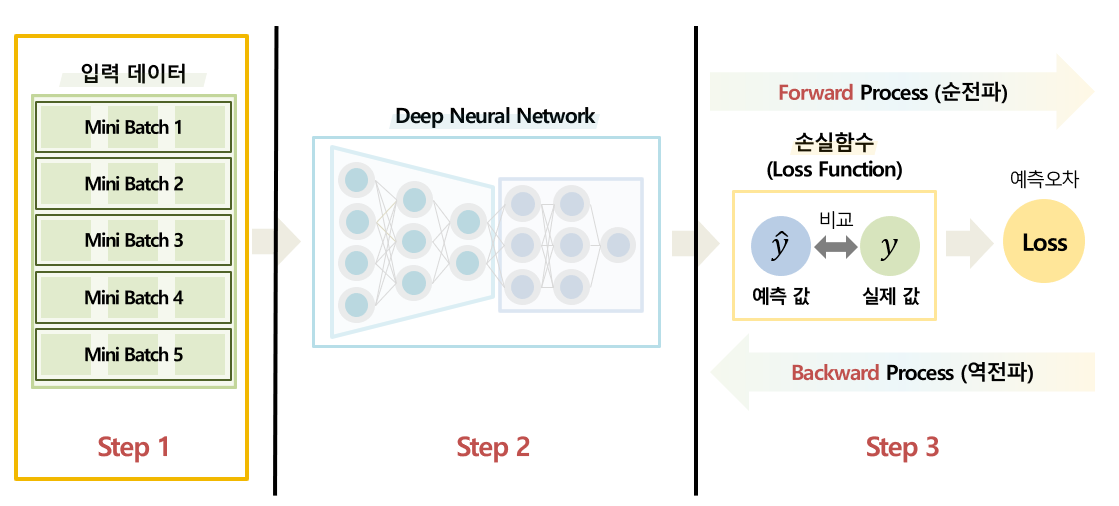

In [7]:
Image('./images/dataset.PNG')

- `데이터셋 정의`: 제품군 선정 (S, A)
- `task 정의`: 단일 output 예측, 여러 개의 outupt 예측
- `전처리 방식 정의`:
    - `범주형 데이터 인코딩`: one-hot, target, etc.
    - `수치형 데이터 정규화`: standard, minmax, robust, etc.
- `학습/검증/평가 데이터 비율 정의` : 6:2:2

In [8]:
# 우리가 바꿔가며 실험해야 할 것
data_configs = {
    'product' : 'A',  # 'S'
    'task' : 'multi',  # 'single'
    'cat_encoding': 'one-hot', # target
    'scaler_type' : 'standard',  # minmax, robust
    'train_ratio' : 0.6,
    'test_ratio' : 0.2
}
configs.update(data_configs)
configs

{'device': 'cuda',
 'seed': 0,
 'product': 'A',
 'task': 'multi',
 'cat_encoding': 'one-hot',
 'scaler_type': 'standard',
 'train_ratio': 0.6,
 'test_ratio': 0.2}

### 데이터 불러오기

In [9]:
# 데이터 load
if configs['product'] == 'A':
    df = pd.read_excel("data/CapL ML Dataset_반출_R2_261103.xlsx")
elif configs['product'] == 'S':
    df = pd.read_csv("data/df_S.csv")
else:
    raise ValueError
df['source_row'] = df.index.astype(str)

# column 정의
icbv_cols = [c for c in df.columns if c.startswith('ICBV_N')]
y_cols = [c for c in df.columns if c.startswith('CapL_')]
cat_cols = [c for c in df.columns if (c.startswith('PROC_') and c.endswith(('_CH', '_RCP', '_EQ'))) or c == 'ICBV_EQ']
time_cols = [c for c in df.columns if c.endswith('_END_TM') and c != 'TEST_END_TM']
input_candidates = cat_cols+icbv_cols

# 데이터 시계열 순 정렬
df = df.drop_duplicates(subset=[c for c in df.columns if c != 'source_row']).copy()
df['feature_time'] = df[time_cols].max(axis=1)
df = df.sort_values(['feature_time', 'source_row']).reset_index(drop=True)

# task 정의
if configs['task'] == 'single':
    df['y'] = df[y_cols].median(axis=1)
    df = df.loc[df['y'].notna()].copy()
    y_cols = ['y']

In [10]:
df

,PROD,LOT_ID,SLOT_ID,PROC_A_CH,PROC_A_END_TM,PROC_A_RCP,PROC_B_CH,PROC_B_END_TM,PROC_B_RCP,PROC_C_CH,PROC_C_END_TM,PROC_C_RCP,PROC_D_CH,PROC_D_END_TM,PROC_D_RCP,PROC_E_CH,PROC_E_END_TM,PROC_E_RCP,PROC_F_CH,PROC_F_END_TM,PROC_F_RCP,ICBV_END_TM,ICBV_EQ,"ICBV_NBV_(-5,1)","ICBV_NBV_(0,-3)","ICBV_NBV_(0,1)","ICBV_NBV_(0,5)","ICBV_NBV_(5,1)","ICBV_NBV_(3,3)","ICBV_NBV_(-3,3)","ICBV_NBV_(-3,-1)","ICBV_NBV_(3,-1)","ICBV_NBV_(3,1)","ICBV_NBV_(0,3)","ICBV_NBV_(-3,1)","ICBV_NBV_(0,-1)","ICBV_NBV_(-2,4)","ICBV_NBV_(2,4)","ICBV_NBV_(-1,3)","ICBV_NBV_(1,3)","ICBV_NBV_(-4,2)","ICBV_NBV_(-2,2)","ICBV_NBV_(2,2)","ICBV_NBV_(4,2)","ICBV_NBV_(-4,0)","ICBV_NBV_(-2,0)","ICBV_NBV_(2,0)","ICBV_NBV_(4,0)","ICBV_NBV_(-1,-1)","ICBV_NBV_(1,-1)","ICBV_NBV_(-2,-2)","ICBV_NBV_(2,-2)","ICBV_NBV_(1,5)","ICBV_NBV_(4,4)","ICBV_NBV_(5,3)","ICBV_NBV_(5,2)","ICBV_NBV_(5,0)","ICBV_NBV_(5,-1)","ICBV_NBV_(4,-2)","ICBV_NBV_(1,-3)","ICBV_NBV_(-1,-3)","ICBV_NBV_(-4,-2)","ICBV_NBV_(-5,-1)","ICBV_NBV_(-5,0)","ICBV_NBV_(-5,2)","ICBV_NBV_(-5,3)","ICBV_NBV_(-4,4)","ICBV_NBV_(-1,5)","ICBV_NBV_(0,2)","ICBV_NBV_(1,1)","ICBV_NBV_(0,0)","ICBV_NBV_(-1,1)",TEST_END_TM,"CapL_(-1,-1)","CapL_(-1,5)","CapL_(5,0)","CapL_(5,1)","CapL_(5,2)","CapL_(5,3)","CapL_(6,-1)","CapL_(6,-2)","CapL_(6,0)","CapL_(6,1)","CapL_(6,2)","CapL_(-2,-1)","CapL_(-2,-2)","CapL_(-2,-3)","CapL_(-2,-4)","CapL_(-2,0)","CapL_(-2,1)","CapL_(-2,2)","CapL_(-2,3)","CapL_(-2,4)","CapL_(-1,-2)","CapL_(-3,-1)","CapL_(-3,-2)","CapL_(-3,-3)","CapL_(-3,-4)","CapL_(-3,0)","CapL_(-3,1)","CapL_(-3,2)","CapL_(-3,3)","CapL_(-3,4)","CapL_(-4,-1)","CapL_(-1,-3)","CapL_(-4,-2)","CapL_(-4,-3)","CapL_(-4,-4)","CapL_(-4,0)","CapL_(-4,1)","CapL_(-4,2)","CapL_(-4,3)","CapL_(-4,4)","CapL_(-5,-1)","CapL_(-5,-2)","CapL_(-1,-4)","CapL_(-5,-3)","CapL_(-5,0)","CapL_(-5,1)","CapL_(-5,2)","CapL_(-5,3)","CapL_(-6,-1)","CapL_(-6,-2)","CapL_(-6,0)","CapL_(-6,1)","CapL_(-6,2)","CapL_(-1,0)","CapL_(0,-1)","CapL_(0,-2)","CapL_(0,-3)","CapL_(0,-4)","CapL_(0,0)","CapL_(0,1)","CapL_(0,2)","CapL_(0,3)","CapL_(0,4)","CapL_(0,5)","CapL_(-1,1)","CapL_(1,-1)","CapL_(1,-2)","CapL_(1,-3)","CapL_(1,-4)","CapL_(1,0)","CapL_(1,1)","CapL_(1,2)","CapL_(1,3)","CapL_(1,4)","CapL_(1,5)","CapL_(-1,2)","CapL_(2,-1)","CapL_(2,-2)","CapL_(2,-3)","CapL_(2,-4)","CapL_(2,0)","CapL_(2,1)","CapL_(2,2)","CapL_(2,3)","CapL_(2,4)","CapL_(3,-1)","CapL_(-1,3)","CapL_(3,-2)","CapL_(3,-3)","CapL_(3,-4)","CapL_(3,0)","CapL_(3,1)","CapL_(3,2)","CapL_(3,3)","CapL_(3,4)","CapL_(4,-1)","CapL_(4,-2)","CapL_(-1,4)","CapL_(4,-3)","CapL_(4,-4)","CapL_(4,0)","CapL_(4,1)","CapL_(4,2)","CapL_(4,3)","CapL_(4,4)","CapL_(5,-1)","CapL_(5,-2)","CapL_(5,-3)",source_row,feature_time
0,A,AJ887,13,613F6_3,2026-03-06 10:10:51,I1R5,703F6_3,2026-03-06 12:55:26,A1R2,902F6_2,2026-03-06 16:38:34,I2R4,903F6_3,2026-03-06 18:25:17,A2R4,203A6_2,2026-03-06 21:11:01,DR3,01734_4,2026-03-07 00:00:46,PLTR0,2026-03-10 15:00:26,10804_1,-49.751256,-50.371887,-51.105497,-49.492560,-50.518581,-50.240313,-50.213741,-50.504247,-50.696989,-50.872731,-50.535867,-50.353006,-51.245167,-50.136168,-49.705350,-50.446151,-50.538581,-50.054048,-50.651464,-50.957232,-50.395173,-50.189407,-50.741204,-51.108569,-50.573225,-51.105045,-51.139807,-51.121045,-50.913279,-49.368605,-49.099148,-49.277651,-50.162550,-50.354077,-49.960784,-50.127692,-50.203908,-50.177431,-50.465937,-50.316315,-49.804090,-49.609086,-49.082909,-49.473726,-49.599039,-50.838063,-51.290263,-51.407908,-51.193380,2026-03-31 09:59:55,9740.618,10454.918,9107.272,9769.190,10640.636,9831.096,8831.076,8969.174,7712.006,9188.226,9445.374,11283.506,11845.422,10931.118,9997.766,10821.592,10416.822,9640.616,9092.986,7983.440,10140.626,13069.256,13583.552,12507.340,9859.668,12697.820,11564.464,10750.162,9050.128,7345.332,14588.334,10297.772,13731.174,11988.282,8464.402,14550.238,13002.588,11802.564,9869.192,7497.716,14959.770,13593.076,9750.142,11731.134,16293.130,15169.298,12926.396,11221.600,13193.068,11773.992,14540.714,14635.954,13583.552,9588.234,9045.366,9764.428,9897.764,10

### 데이터셋 전처리

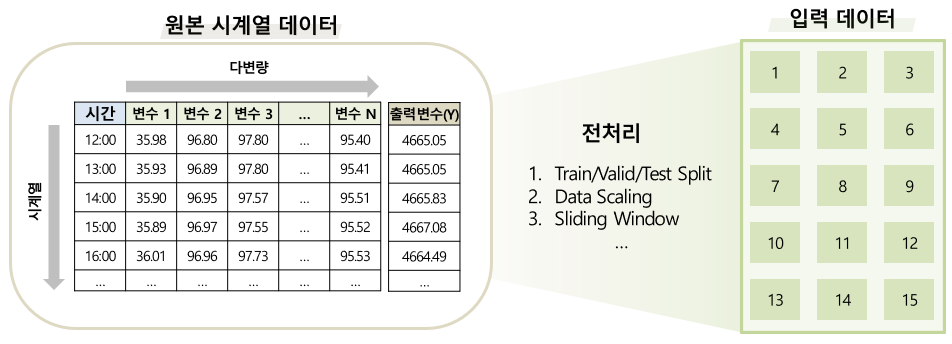

In [11]:
Image('./images/preprocess.PNG')

In [12]:
# 데이터 순차 분할
valid_start = df.iloc[int(len(df) * configs['train_ratio'])]['feature_time']
test_start = df.iloc[int(len(df) * (1-configs['test_ratio']))]['feature_time']
is_valid = (df['feature_time'] >= valid_start) & (df['feature_time'] < test_start)

df_train = df.loc[df['feature_time'] < valid_start].copy()
df_valid = df.loc[is_valid].copy()
df_test = df.loc[df['feature_time'] >= test_start].copy()

In [13]:
# 이상 값 처리
def fit_sigma_bounds(y_train, k:int=6, floor:int=1000):
    """train y로 측정 위치(컬럼)별 [lower, upper] 범위를 계산"""
    bounds = {}
    for column in y_train.columns:
        values = y_train[column].dropna().to_numpy(dtype=float)
        center = np.median(values)  # median ± 6σ, σ = IQR/1.349 (극단값에 σ가 부풀지 않음)
                                    # cf. 표준정규분포에서 Q3-Q1 = 2x0.6745σ = 1.349σ
        q25, q75 = np.percentile(values, [25, 75])
        sigma = (q75 - q25) / 1.349

        lower = center - k * sigma
        if floor is not None:  # # 6σ 하한은 음수라 7.09 같은 측정 실패값을 못 거르므로 물리 하한을 추가
            lower = max(lower, floor)
        bounds[column] = (lower, center + k * sigma)
    return pd.DataFrame(bounds, index=['lower', 'upper']).T

def remove_out_of_bounds(table, bounds):
    """범위 밖 CapL 점은 NaN으로 바꾸고(점 단위 제거), 유효한 점이 하나도 없는 wafer는 제외"""
    y = table[bounds.index]
    outside = y.lt(bounds['lower'], axis=1) | y.gt(bounds['upper'], axis=1)
    cleaned = table.copy()
    cleaned[bounds.index] = y.mask(outside)
    has_target = cleaned[bounds.index].notna().any(axis=1)
    return cleaned.loc[has_target].copy()

In [14]:
capl_bounds = fit_sigma_bounds(df[y_cols])
clean_splits, filter_rows = {}, []

# train
df_train_cleaned = remove_out_of_bounds(df_train, capl_bounds)
before_points = int(df_train[y_cols].notna().sum().sum())
after_points = int(df_train_cleaned[y_cols].notna().sum().sum())
filter_rows.append({
    'wafers_before': len(df_train), 'wafers_after': len(df_train_cleaned),
    'removed_points': before_points - after_points,
    'removed_ratio': 1 - after_points / before_points,})

# valid
df_valid_cleaned = remove_out_of_bounds(df_valid, capl_bounds)
before_points = int(df_valid[y_cols].notna().sum().sum())
after_points = int(df_valid_cleaned[y_cols].notna().sum().sum())
filter_rows.append({
    'wafers_before': len(df_valid), 'wafers_after': len(df_valid_cleaned),
    'removed_points': before_points - after_points,
    'removed_ratio': 1 - after_points / before_points,})

# test
df_test_cleaned = remove_out_of_bounds(df_test, capl_bounds)
before_points = int(df_test[y_cols].notna().sum().sum())
after_points = int(df_test_cleaned[y_cols].notna().sum().sum())
filter_rows.append({
    'wafers_before': len(df_test), 'wafers_after': len(df_test_cleaned),
    'removed_points': before_points - after_points,
    'removed_ratio': 1 - after_points / before_points,})
display(pd.DataFrame(filter_rows).round(4))
display(capl_bounds.describe().round(0))

,wafers_before,wafers_after,removed_points,removed_ratio
0,643,643,956,0.0138
1,214,211,673,0.0291
2,215,215,288,0.0124


,lower,upper
count,108.0,108.0
mean,1000.0,26082.0
std,0.0,7557.0
min,1000.0,17067.0
25%,1000.0,21300.0
50%,1000.0,24664.0
75%,1000.0,28933.0
max,1000.0,61074.0


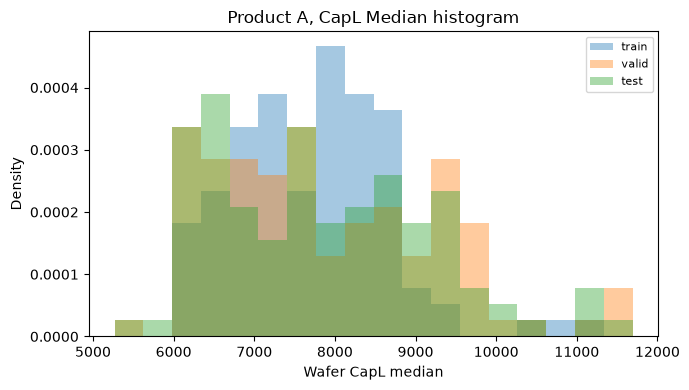

In [15]:
fig, ax = plt.subplots(1,1, figsize=(7,4))
all_y = pd.concat([df_train_cleaned[y_cols].median(), df_valid_cleaned[y_cols].median(), df_test_cleaned[y_cols].median()])
bins = np.histogram_bin_edges(all_y, bins=18)
splits=['train','valid','test']
for i, df in enumerate([df_train_cleaned, df_valid_cleaned, df_test_cleaned]):
    ax.hist(df[y_cols].median(), bins=bins, density=True, alpha=0.4, label=splits[i])
ax.set(title=f"Product {configs['product']}, CapL Median histogram", xlabel='Wafer CapL median', ylabel='Density')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [16]:
# 데이터 결측치 처리
split_data = {'train': df_train_cleaned, 'valid': df_valid_cleaned, 'test': df_test_cleaned}
def filter_inputs(split_tables):
    # 결측 상황 확인
    missing_rate = split_tables['train'][input_candidates].isna().mean()
    selected_columns = []
    retained_negative = []
    for column in input_candidates:
        if missing_rate[column] < 0.7:
            selected_columns.append(column)
            if column in icbv_cols:
                retained_negative.append(column)

    # 결측률이 70% 이상인 행을 제외
    filtered = {}
    for split in ['train', 'valid', 'test']:
        table = split_tables[split]
        row_missing_rate = table[selected_columns].isna().mean(axis=1)
        filtered[split] = table.loc[row_missing_rate < 0.7].copy()
        assert filtered[split][retained_negative].notna().any(axis=1).all()

    return filtered, selected_columns, retained_negative

In [17]:
# 학습, 검증, 평가 데이터셋에 대한 전처리
train, valid, test = split_data['train'], split_data['valid'], split_data['test']
assert train['feature_time'].max() < valid['feature_time'].min()
assert valid['feature_time'].max() < test['feature_time'].min()

tables, input_cols, icbv = filter_inputs(split_data)
tables = {k: v[input_cols + y_cols + ['source_row']] for k, v in tables.items()}

# 학습, 검증, 평가 데이터셋 정의
df_train, df_valid, df_test = tables['train'], tables['valid'], tables['test']

In [18]:
# 데이터셋 정의
def prepare_inputs(df_train, df_valid, df_test, target_columns=None):
    # 정답(y) 컬럼 전체와 식별용 source_row는 입력에서 제외
    target_columns = list(y_cols if target_columns is None else target_columns)
    X_table = df_train.drop(columns=target_columns + ['source_row'])
    numeric_columns = X_table.select_dtypes(include='number').columns.tolist()
    category_columns = X_table.select_dtypes(exclude='number').columns.tolist()

    """Data scaling"""
    medians = X_table[numeric_columns].median()
    # 사전에 정의해둔 configuration에 맞게 scaler 정의
    scaler = {
    "standard": StandardScaler,
    "minmax": MinMaxScaler,
    "robust": RobustScaler,
            }[configs['scaler_type']]().fit(X_table[numeric_columns].fillna(medians))
    train_category = X_table[category_columns].astype('string').fillna('__MISSING__').astype(object)
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.float32)
    encoder.fit(train_category)

    inputs = []
    for table in [df_train, df_valid, df_test]:
        observed = table[numeric_columns].notna().to_numpy(dtype=np.float32)
        numeric = scaler.transform(table[numeric_columns].fillna(medians))
        category = table[category_columns].astype('string').fillna('__MISSING__').astype(object)
        category = encoder.transform(category)
        X = np.concatenate([numeric, observed, category], axis=1).astype(np.float32)
        assert np.isfinite(X).all()
        inputs.append(X)
    return inputs[0], inputs[1], inputs[2]

In [19]:
def fit_y_scaler(y_train):
    """Fit per-output median / IQR on TRAIN y only."""
    y_train = pd.DataFrame(y_train)
    y_median = y_train.median().to_numpy(dtype=np.float32)                        # (n_outputs,)
    y_iqr = (y_train.quantile(0.75) - y_train.quantile(0.25)).to_numpy(dtype=np.float32)
    y_scale = np.maximum(y_iqr, 1.0).astype(np.float32)                            # (n_outputs,)
    assert np.isfinite(y_median).all(), 'an output column has no valid value'
    return y_median, y_scale

In [20]:
X_train, X_valid, X_test = prepare_inputs(df_train, df_valid, df_test, y_cols)
y_train, y_valid, y_test = df_train[y_cols], df_valid[y_cols], df_test[y_cols]

### Sliding Window

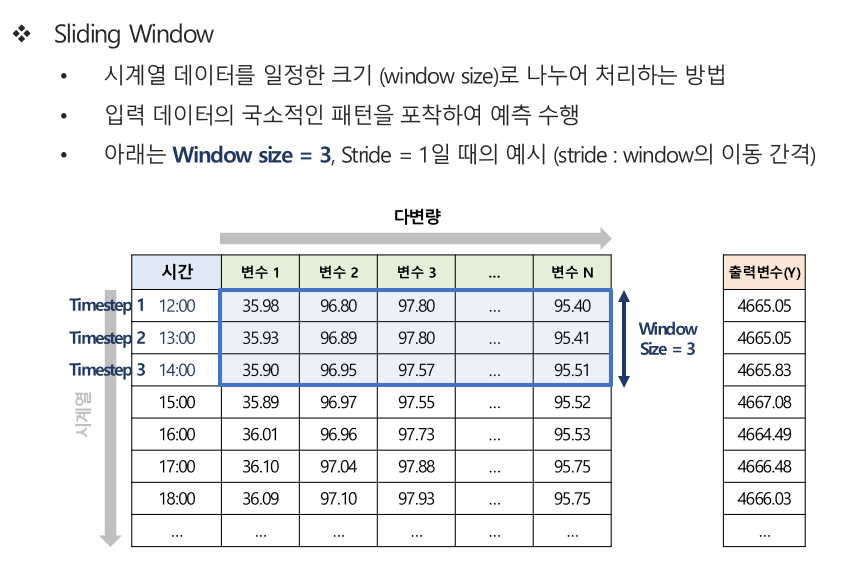

In [21]:
Image('./images/sliding_window1.PNG')

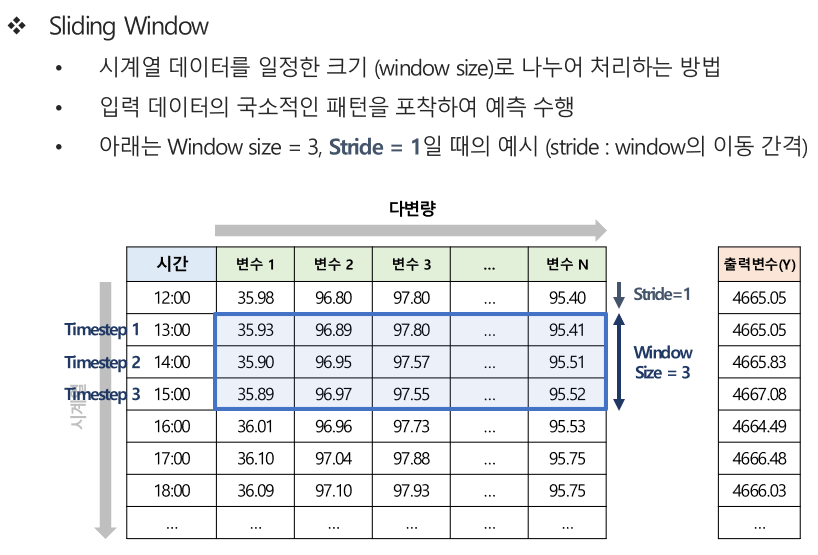

In [22]:
Image('./images/sliding_window2.PNG')

In [23]:
data_configs = {
    'window_size': 1,   
    'stride' : 1,       
    'y_mode' : 'last'   # 'avg', 'last', 'next'
}
configs.update(data_configs)
configs

{'device': 'cuda',
 'seed': 0,
 'product': 'A',
 'task': 'multi',
 'cat_encoding': 'one-hot',
 'scaler_type': 'standard',
 'train_ratio': 0.6,
 'test_ratio': 0.2,
 'window_size': 1,
 'stride': 1,
 'y_mode': 'last'}

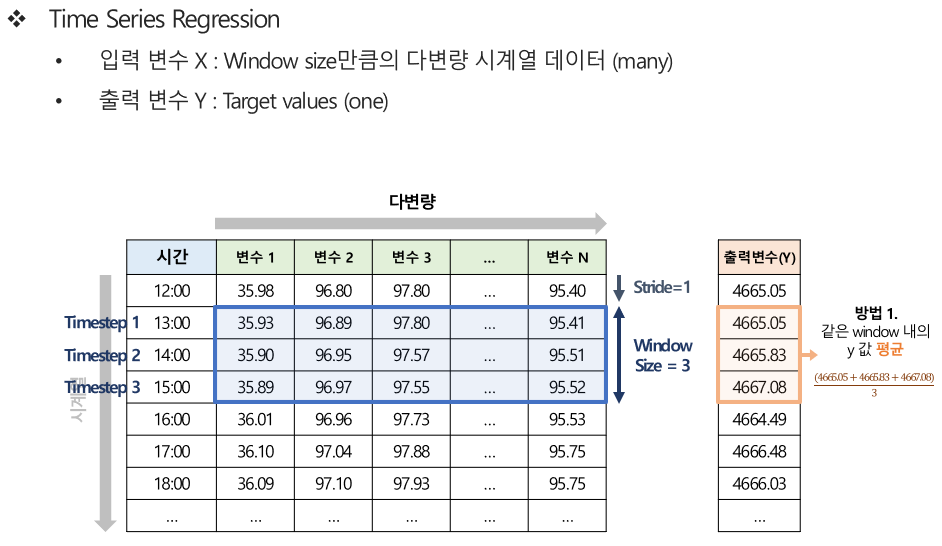

In [24]:
Image('./images/reg_y1.PNG')

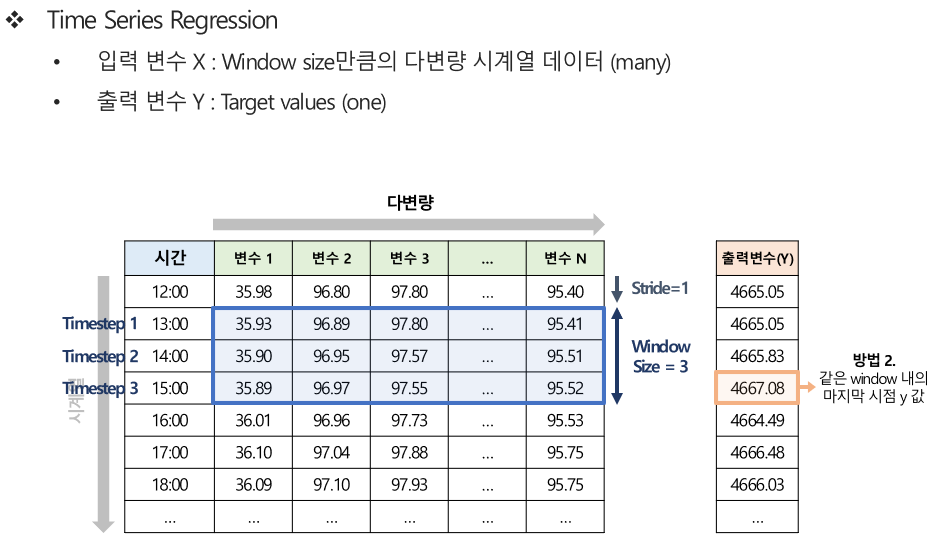

In [25]:
Image('./images/reg_y2.PNG')

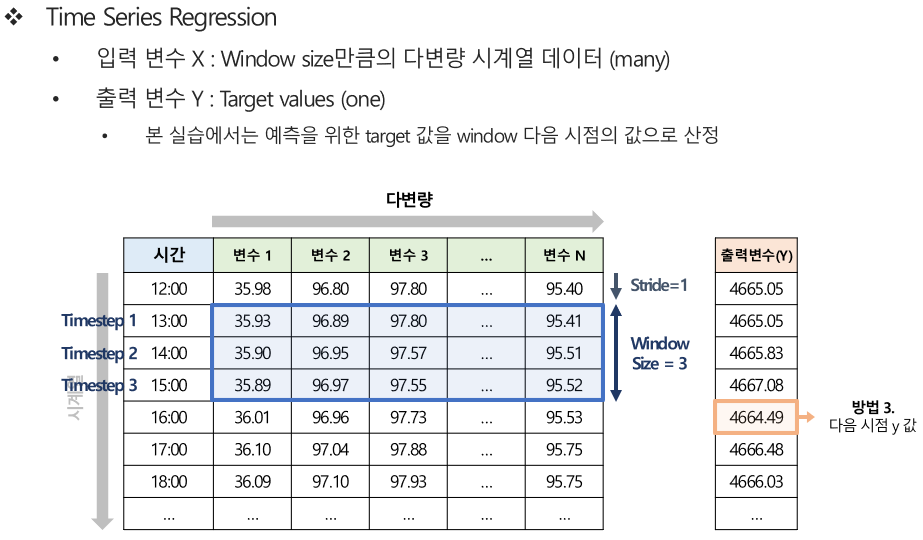

In [26]:
Image('./images/reg_y3.PNG')

In [27]:
def sliding_window(X, y, window_size:int=1, stride_size:int=1, y_mode:str='last'):
    """
    Sliding Window를 적용해주는 함수
    - time series data인 X, y를 모두 input으로 받습니다
    - 사용자가 window size (int형), stride size (int형)을 지정해줍니다
    - y_mode:
        (1) "avg"일 시 window 내의 평균
        (2) "last"일 시 마지막 window의 y 값, 
        (3) "next"일 시 window 바로 다음 timestep의 y 값으로 정의합니다.
            - 이 경우, X data의 마지막 window sample은 y 값이 없으므로 샘플을 제거합니다.
    """
    X = np.asarray(X)
    y = np.asarray(y, dtype=np.float32)
    starts = range(0, X.shape[0] - window_size + 1, stride_size)
    x_window = np.array([X[s:s+window_size] for s in starts])
    
    if y_mode=="avg":
        y_window = np.array([np.nanmean(y[s:s+window_size], axis=0) for s in starts]) # per-output mean

    elif y_mode=="last":
        y_window = np.array([y[start+window_size-1] for start in range(0, y.shape[0]-window_size+1, stride_size)])

    elif y_mode=="next":
        y_window = np.array([y[start+window_size] for start in range(0, y.shape[0]-window_size, stride_size)])
        x_window = x_window[:len(y_window)]  # y 관측치 개수와 동일하게 맞추기
        
    return x_window, y_window

In [28]:
def make_windows(configs):
    args = (configs['window_size'], configs['stride'], configs['y_mode'])
    X_tr, y_tr = sliding_window(X_train, y_train, *args)
    X_va, y_va = sliding_window(X_valid, y_valid, *args)
    X_te, y_te = sliding_window(X_test,  y_test,  *args)
    return X_tr, y_tr, X_va, y_va, X_te, y_te

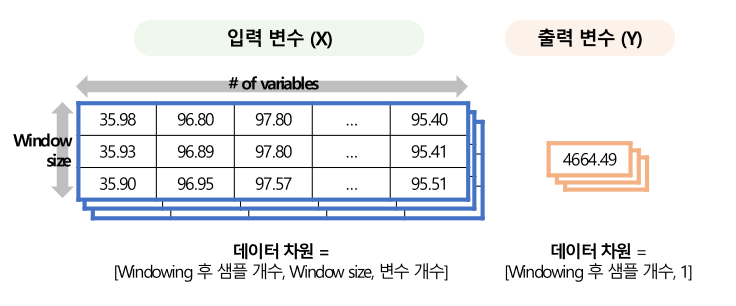

In [29]:

Image('./images/sliding_window_samples.PNG')

In [30]:
## 데이터의 차원 확인 ##
X_train_window, y_train_window, \
    X_valid_window, y_valid_window, \
        X_test_window, y_test_window  = make_windows(configs)

print(f"학습 데이터의 차원: 입력 데이터 {X_train_window.shape}, 출력 데이터 {y_train_window.shape}")
print(f"검증 데이터의 차원: 입력 데이터 {X_valid_window.shape}, 출력 데이터 {y_valid_window.shape}")
print(f"평가 데이터의 차원: 입력 데이터 {X_test_window.shape}, 출력 데이터 {y_test_window.shape}")

학습 데이터의 차원: 입력 데이터 (643, 1, 336), 출력 데이터 (643, 108)
검증 데이터의 차원: 입력 데이터 (211, 1, 336), 출력 데이터 (211, 108)
평가 데이터의 차원: 입력 데이터 (215, 1, 336), 출력 데이터 (215, 108)


### 데이터셋과 로더를 정의

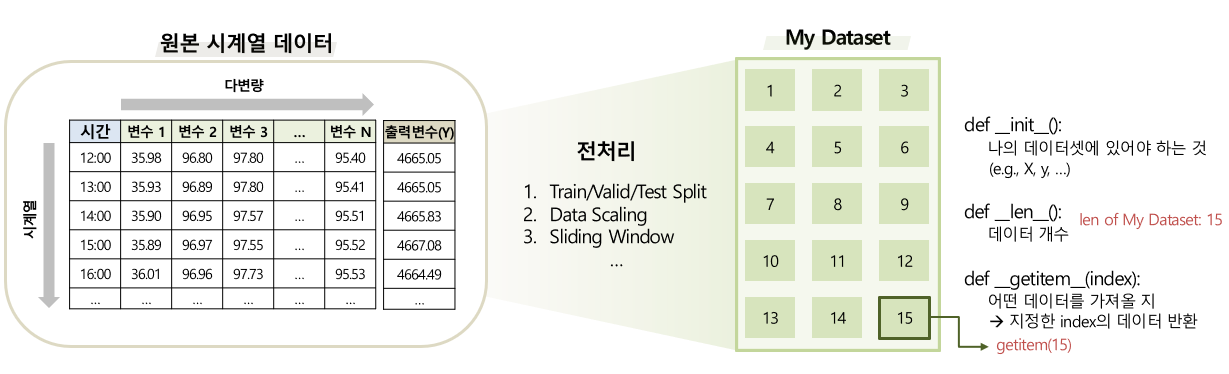

In [31]:
Image('./images/custom_dataset.PNG')

In [32]:
class CustomDataset(Dataset):
  def __init__(self):
    """객체가 생성될 때 초기화를 위해 호출하는 특수 메서드.
        데이터셋 구축을 위해 필요한 초기 설정을 수행하는 부분. (데이터 불러오기, 전처리 등)"""
    self.X = np.random.rand(5, 3)
    self.Y = np.random.randint(1, 5, (5,))

  def __len__(self):
    """데이터셋의 길이. 총 샘플의 수를 반환.
        len을 통해서 getitem의 idx 범위가 결정"""
    return len(self.X)

  def __getitem__(self, idx): 
    """인덱스(idx)를 입력받아, 이에 대응되는 데이터를 return.
        데이터를 로드하고 (필요 시) 전처리 후 반환 필요"""
    return {'X': torch.tensor(self.X[idx]).float(),
            'Y': torch.tensor(self.Y[idx]).long()}

In [33]:
mydataset = CustomDataset()
print("데이터셋 총 샘플 수 확인: ", mydataset.__len__())
print("데이터셋 0번째 샘플 가져오기: ", mydataset.__getitem__(0))
print("데이터셋 0번째 X 샘플 가져오기: ", mydataset.__getitem__(0)['X'])

데이터셋 총 샘플 수 확인:  5
데이터셋 0번째 샘플 가져오기:  {'X': tensor([0.7289, 0.2199, 0.2024]), 'Y': tensor(4)}
데이터셋 0번째 X 샘플 가져오기:  tensor([0.7289, 0.2199, 0.2024])


In [34]:
class iTAP_Dataset(Dataset):
    def __init__(self, X, y, y_median, y_scale):
        y = np.asarray(y, dtype=np.float32)           # (N, n_outputs), NaN = removed point
        mask = np.isfinite(y).astype(np.float32)      # 1 = valid, 0 = removed
        y_scaled = np.where(mask > 0, (y - y_median) / y_scale, 0.0).astype(np.float32)
        assert mask.sum(axis=1).min() > 0, 'a sample has no valid y'

        self.X = torch.from_numpy(np.asarray(X, dtype=np.float32))  # (N, window, features)
        self.y = torch.from_numpy(y_scaled)
        self.mask = torch.from_numpy(mask)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx], self.mask[idx]

    @property
    def input_dim(self):
        # X의 변수 개수 (차원)을 반환
        return self.X.shape[-1]

    @property
    def window_size(self):
        return self.X.shape[1]


In [35]:
data_configs = {
    'batch_size':256
}
configs.update(data_configs)
configs

{'device': 'cuda',
 'seed': 0,
 'product': 'A',
 'task': 'multi',
 'cat_encoding': 'one-hot',
 'scaler_type': 'standard',
 'train_ratio': 0.6,
 'test_ratio': 0.2,
 'window_size': 1,
 'stride': 1,
 'y_mode': 'last',
 'batch_size': 256}

In [36]:
def get_dataloader(X_train, y_train, X_valid, y_valid, X_test, y_test, batch_size:int, seed:int=0):
    y_median, y_scale = fit_y_scaler(y_train) # using train statistics only

    train_dataset = iTAP_Dataset(X_train, y_train, y_median, y_scale)
    valid_dataset = iTAP_Dataset(X_valid, y_valid, y_median, y_scale)
    test_dataset  = iTAP_Dataset(X_test,  y_test,  y_median, y_scale)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                              generator=torch.Generator().manual_seed(seed))
    valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False)
    test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False)
    return train_loader, valid_loader, test_loader, y_median, y_scale

In [37]:
train_loader, valid_loader, test_loader, y_median, y_scale = get_dataloader(
    X_train_window, y_train_window,
    X_valid_window, y_valid_window,
    X_test_window,  y_test_window,
    configs['batch_size'], configs['seed'],
)

X_b, y_b, m_b = next(iter(train_loader))
print(X_b.shape, y_b.shape, m_b.shape)   # (B, window, features), (B, 108), (B, 108)

torch.Size([256, 1, 336]) torch.Size([256, 108]) torch.Size([256, 108])


-----

# 2. 모델 정의

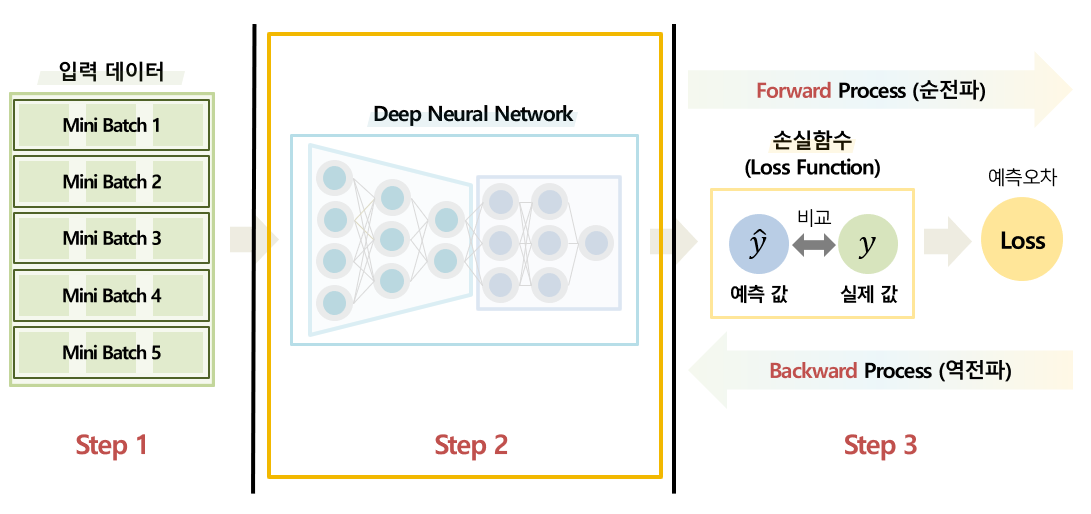

In [38]:
Image('./images/model.PNG')

- `어떤 모델을 이용할지`: MLP, 1D CNN, RNN, LSTM
- `모델의 차원 (hidden dimension)`
- `모델 층을 얼마나 쌓을 것인지 (num_layers)`
- `과적합 방지 기법`
    - `use_batchnorm`
    - `dropout_rate`

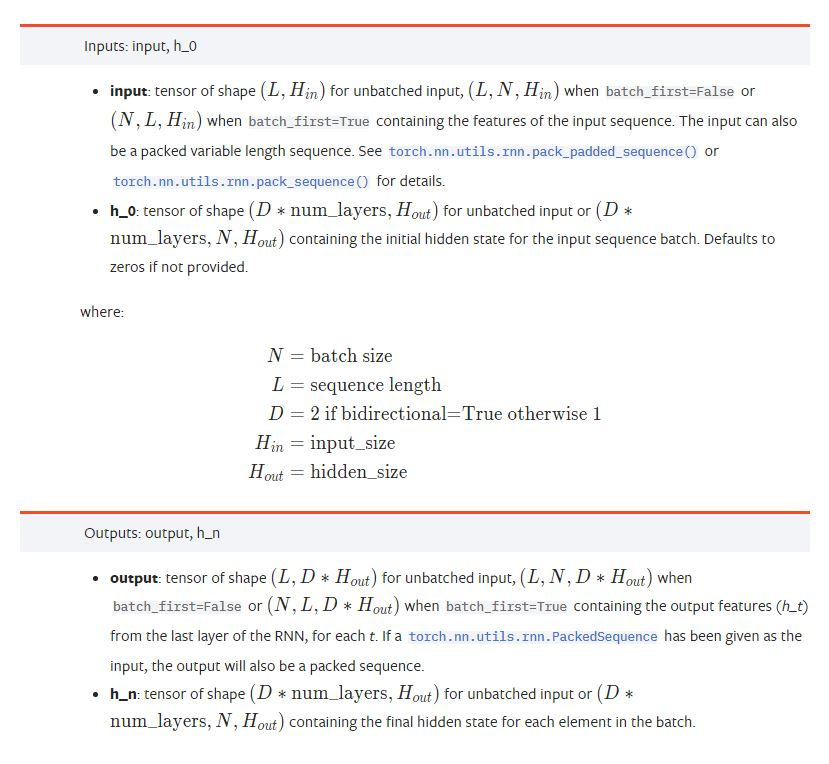

In [39]:
Image('./images/RNN.JPG')

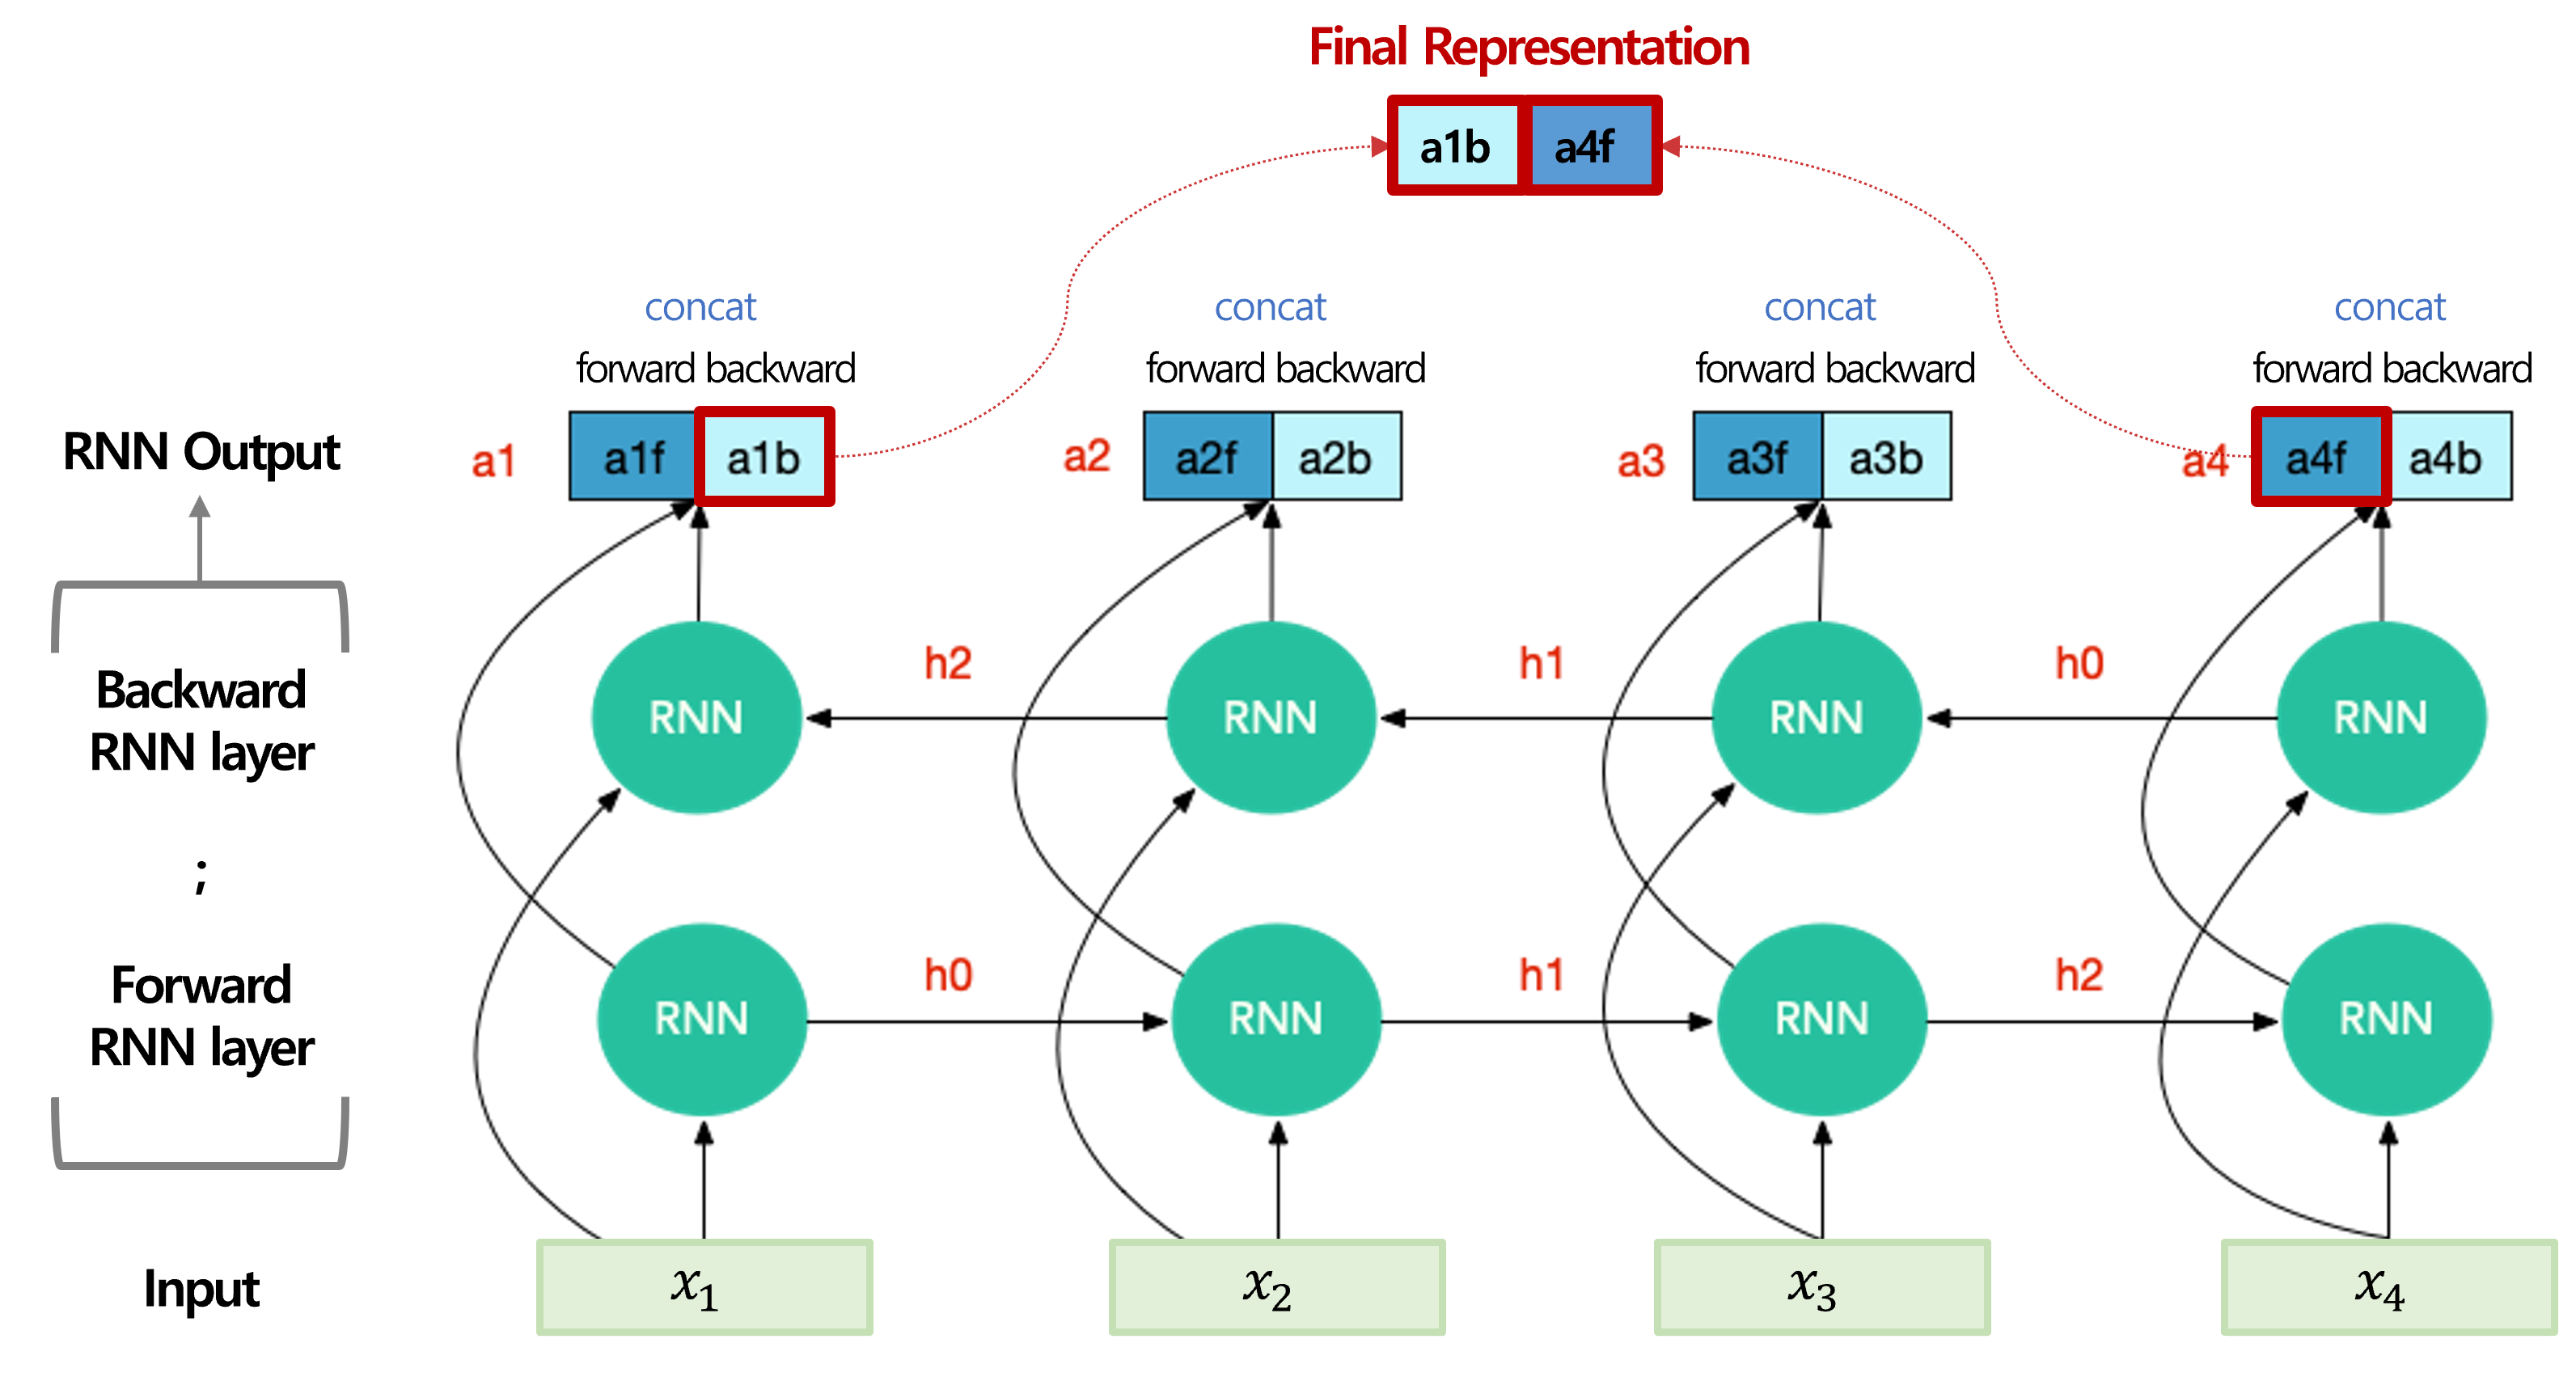

In [40]:
Image('./images/BiRNN.PNG')

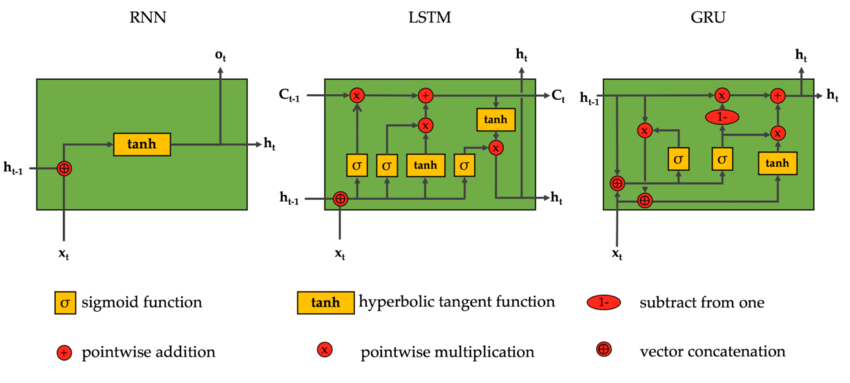

In [41]:
Image('./images/rnn_variants.png')

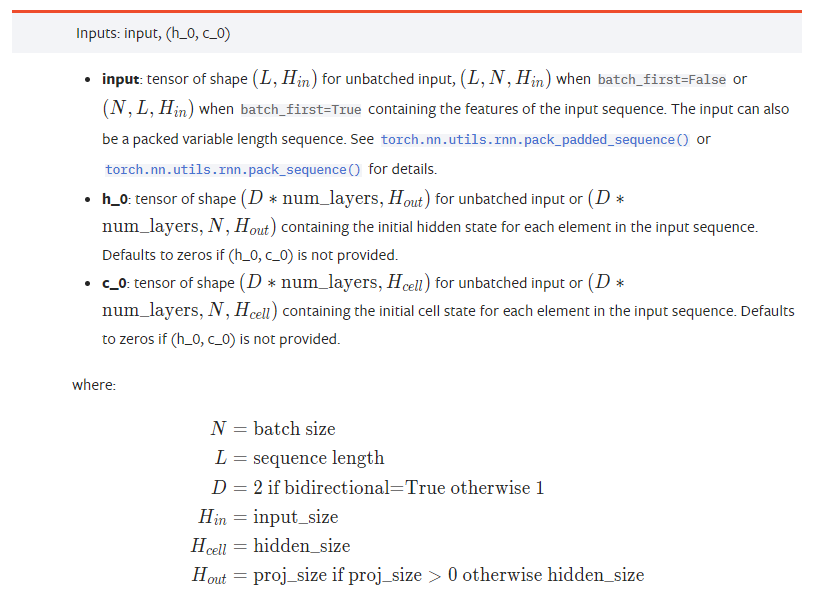

In [42]:
Image('./images/lstm_input.PNG')

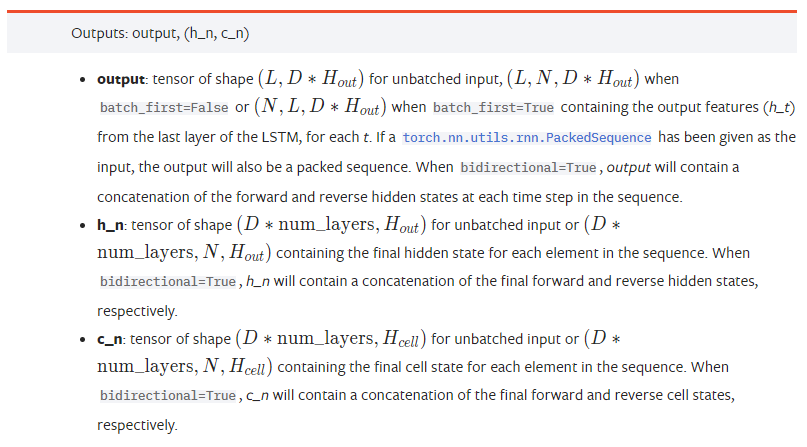

In [43]:
Image('./images/lstm_out.PNG')

- LSTM의 경우, RNN과 GRU와 달리 initial cell state도 함께 정의해야 하며, hidden states 뿐만 아니라 cell states도 함께 반환됨에 주의

In [44]:
# 우리가 바꿔가며 실험해야 할 것
model_configs = {
    'rnn_type': 'RNN',       # 'RNN', 'LSTM', 'GRU' 중 선택 (str)
    'hidden_size': 64,       # RNN 레이어가 가지는 은닉 노드 수 (int)
    'num_layers': 2,         # RNN 레이어를 몇 개 쌓을지 (int)
    'bidirectional': True,   # 단방향/양방향 여부 (bool: True or False)
    'dropout_rate': .1,      # dropout prob.
    'use_batchnorm': True
}

configs.update(model_configs)
configs

{'device': 'cuda',
 'seed': 0,
 'product': 'A',
 'task': 'multi',
 'cat_encoding': 'one-hot',
 'scaler_type': 'standard',
 'train_ratio': 0.6,
 'test_ratio': 0.2,
 'window_size': 1,
 'stride': 1,
 'y_mode': 'last',
 'batch_size': 256,
 'rnn_type': 'RNN',
 'hidden_size': 64,
 'num_layers': 2,
 'bidirectional': True,
 'dropout_rate': 0.1,
 'use_batchnorm': True}

In [45]:
class RNNModel(nn.Module):
    def __init__(self, configs, input_dim, num_outputs):
        super(RNNModel, self).__init__()

        self.configs = configs
        self.input_dim = input_dim
        self.hidden_size = configs['hidden_size']      # 64
        self.num_layers = configs['num_layers']        # 1
        self.bidirectional = configs['bidirectional']  # True
        self.dropout_rate = configs['dropout_rate']

        """모델이 정의되는 방식
        self.rnn = nn.RNN(
            input_size = configs['input_dim'],
            hidden_size = self.hidden_size,
            num_layers = self.num_layers,
            batch_first = True,
            bidirectional = self.bidirectional,
            dropout=self.dropout_rate
        )
        """

        self.rnn_type = configs['rnn_type']
        assert self.rnn_type in ['RNN', 'LSTM', 'GRU'], self.rnn_type

        self.rnn_model = getattr(nn, self.rnn_type)(    # getattr(class, "name")
            input_size = self.input_dim,
            hidden_size = self.hidden_size,
            num_layers = self.num_layers,
            batch_first = True,
            bidirectional = self.bidirectional,
            dropout = self.dropout_rate
        )

        out_dim = self.hidden_size * 2 if self.bidirectional else self.hidden_size
        self.regressor = nn.Linear(in_features=out_dim, out_features=num_outputs)

    def forward(self, x):
        
        # Initial hidden state 초기화
        num_direction = self.num_layers*2 if self.bidirectional else self.num_layers
        h0 = torch.zeros(num_direction, x.size(0), self.hidden_size, device=x.device)

        if self.rnn_type == 'LSTM':
            # lstm의 경우 initial cell state 초기화
            c0 = torch.zeros(num_direction, x.size(0), self.hidden_size, device=x.device)
        
        # 시계열 데이터의 특징 추출
            # out = 모든 timestep에 대한 hidden state 값 (Batch size, Sequence length, D*H_out)
            # last_hidden = 마지막 timestep에 대한 hidden state 값 (D*num_layers, Batch size, H_out)
        init_state = (h0, c0) if self.rnn_type == 'LSTM' else h0
        out, last_hidden = self.rnn_model(x, init_state)

        # 양방향 RNN인 경우: 마지막 layer의 단방향, 역방향 layer hidden state를 결합 (concatenate)
        # 단방향 RNN인 경우: 가장 마지막 timestep에 대한 hidden state 값 
        last_hidden = last_hidden[0] if self.rnn_type == "LSTM" else last_hidden # (hidden states, cell states) 중 hidden states만 선택
        last_out = torch.cat((last_hidden[-2, :, :], last_hidden[-1, :, :]), dim=1) if self.bidirectional else out[:, -1, :]
       
        # 추출된 특징을 regressor에 넣고, 회귀 예측 수행
        pred = self.regressor(last_out)
        
        return pred

In [46]:
class MLP(nn.Module):
    def __init__(self, configs, input_dim, num_outputs):
        super().__init__()
        layers, in_features = [], input_dim * configs['window_size']  # flattened window
        for hidden in configs['mlp_hidden_dims']:
            layers.append(nn.Linear(in_features, hidden))
            if configs['use_batchnorm']:
                layers.append(nn.BatchNorm1d(hidden))
            layers += [nn.ReLU(), nn.Dropout(configs['dropout_rate'])]
            in_features = hidden
        layers.append(nn.Linear(in_features, num_outputs))
        self.net = nn.Sequential(*layers)

    def forward(self, x):                  # x: (B, T, F)
        return self.net(x.flatten(start_dim=1))   # (B, T*F) -> (B, n_outputs)


class CNN1D(nn.Module):
    def __init__(self, configs, input_dim, num_outputs):
        super().__init__()
        k = configs['kernel_size']
        assert k % 2 == 1, 'kernel_size must be odd to keep sequence length'
        layers, in_ch = [], input_dim                          # features = channels
        for out_ch in configs['cnn_channels']:
            layers.append(nn.Conv1d(in_ch, out_ch, kernel_size=k, padding=k // 2))
            if configs['use_batchnorm']:
                layers.append(nn.BatchNorm1d(out_ch))
            layers += [nn.ReLU(), nn.Dropout(configs['dropout_rate'])]
            in_ch = out_ch
        self.conv = nn.Sequential(*layers)
        self.pool = configs['cnn_pool']
        self.regressor = nn.Linear(in_ch, num_outputs)

    def forward(self, x):                  # x: (B, T, F)
        h = self.conv(x.transpose(1, 2))   # (B, F, T) -> (B, C, T)
        h = h[:, :, -1] if self.pool == 'last' else h.mean(dim=-1)   # (B, C)
        return self.regressor(h)

In [47]:
model_configs['backbone'] = 'RNN'  # CNN, MLP

configs.update(model_configs)
configs

{'device': 'cuda',
 'seed': 0,
 'product': 'A',
 'task': 'multi',
 'cat_encoding': 'one-hot',
 'scaler_type': 'standard',
 'train_ratio': 0.6,
 'test_ratio': 0.2,
 'window_size': 1,
 'stride': 1,
 'y_mode': 'last',
 'batch_size': 256,
 'rnn_type': 'RNN',
 'hidden_size': 64,
 'num_layers': 2,
 'bidirectional': True,
 'dropout_rate': 0.1,
 'use_batchnorm': True,
 'backbone': 'RNN'}

In [48]:
def build_model(configs, input_dim, num_outputs):
    backbone = configs['backbone']
    if backbone == 'MLP':
        return MLP(configs, input_dim, num_outputs)
    if backbone == 'CNN':
        return CNN1D(configs, input_dim, num_outputs)
    if backbone == 'RNN':
        return RNNModel(configs, input_dim, num_outputs)
    raise ValueError(f"unknown backbone: {backbone}")

In [49]:
model = build_model(configs, train_loader.dataset.input_dim, len(y_cols))
model

RNNModel(
  (rnn_model): RNN(336, 64, num_layers=2, batch_first=True, dropout=0.1, bidirectional=True)
  (regressor): Linear(in_features=128, out_features=108, bias=True)
)

-----

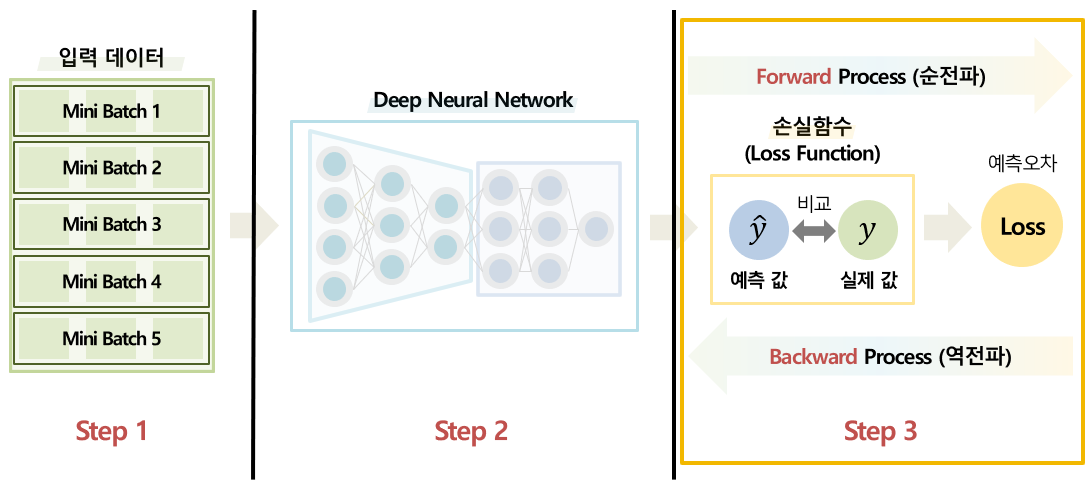

In [67]:
Image('./images/train.PNG')

### Loss function과 optimizer 정의

In [50]:
def criterion(pred, y, mask=None):
    # criterion must be built with reduction='none'
    point_loss = nn.MSELoss(reduction='none')(pred, y)                       # (B, n_outputs)
    return (point_loss * mask).sum() / mask.sum().clamp_min(1)

if configs['task']!='multi': criterion = nn.MSELoss()

In [ ]:
opt_configs = {
    'optimizer':'adam',
    'lr':1e-4,
    'momentum':0.9,
    'weight_decay':0.0  # regularization
}

configs.update(opt_configs)
configs

{'device': 'cuda',
 'seed': 0,
 'product': 'A',
 'task': 'multi',
 'cat_encoding': 'one-hot',
 'scaler_type': 'standard',
 'train_ratio': 0.6,
 'test_ratio': 0.2,
 'window_size': 1,
 'stride': 1,
 'y_mode': 'last',
 'batch_size': 256,
 'rnn_type': 'RNN',
 'hidden_size': 64,
 'num_layers': 2,
 'bidirectional': True,
 'dropout_rate': 0.1,
 'use_batchnorm': True,
 'backbone': 'RNN',
 'optimizer': 'adam',
 'lr': 0.0001,
 'momentum': 0.9,
 'weight_decay': 0.0}

In [52]:
def get_optimizer(configs, model):
    if configs['optimizer'] == "sgd":
        optimizer = optim.SGD(params=model.parameters(), lr=configs['lr'],
                              momentum=configs['momentum'], weight_decay=configs['weight_decay'])

    elif configs['optimizer'] == "adam":
        optimizer = optim.Adam(params=model.parameters(), lr=configs['lr'], 
                                    betas=(configs['momentum'], 0.999), # (momentum, adaptive lr momentum)
                                    weight_decay=configs['weight_decay'])
    else:
        raise ValueError("Invalid optimizer name, it should be one of ['sgd', 'adam'].")

    return optimizer

### Forward & Backward

In [ ]:
# 학습에 필요한 하이퍼파라미터 정의
train_configs = {
    'num_epochs':500,
    'visualize': True,
    'save_dir': './results',
    'patience':30  # validation loss가 다시 떨어질 때까지 기다리는 epoch 횟수 (이를 넘으면 모델 저장 후 학습 조기종료)
}

configs.update(train_configs)
configs

{'device': 'cuda',
 'seed': 0,
 'product': 'A',
 'task': 'multi',
 'cat_encoding': 'one-hot',
 'scaler_type': 'standard',
 'train_ratio': 0.6,
 'test_ratio': 0.2,
 'window_size': 1,
 'stride': 1,
 'y_mode': 'last',
 'batch_size': 256,
 'rnn_type': 'RNN',
 'hidden_size': 64,
 'num_layers': 2,
 'bidirectional': True,
 'dropout_rate': 0.1,
 'use_batchnorm': True,
 'backbone': 'RNN',
 'optimizer': 'adam',
 'lr': 0.0001,
 'momentum': 0.9,
 'weight_decay': 0.0,
 'num_epochs': 500,
 'visualize': True,
 'save_dir': './results',
 'patience': 30}

### Train 과정 함수화

In [54]:
def train(device, model, trainloader, criterion, optimizer):
    model.train()
    total_loss, total_points = 0.0, 0.0

    for X, y, mask in trainloader:
        # X, y, mask 데이터 명시, 두 텐서를 모델, 목적함수와 같은 device로
        X, y, mask = X.to(device), y.to(device), mask.to(device)

        # forward
        # model에 입력 데이터 x를 넣으면 자동으로 forward 함수가 호출되어 prediction 값을 output으로 도출
        pred = model(X)

        # Loss 계산
        loss = criterion(pred, y, mask)

        """Optimizer Gradient 초기화"""
        optimizer.zero_grad()

        """계산된 loss에서 gradient를 계산하는 역전파 함수: .backward()"""
        loss.backward()  # PyTorch 자동 미분

        """optimizer를 이용한 파라미터 업데이트"""
        optimizer.step()

        n = mask.sum().item()
        total_loss += loss.item() * n           # weight by number of valid points
        total_points += n

    return {'loss': total_loss / total_points}

### Valid (Evaluate) 과정 함수화

In [55]:
@torch.no_grad()
def evaluate(device, model, validloader, criterion):
    model.eval() # batchnorm, dropout 등 train할 때와 test할 때 연산이 다른 경우가 존재
    total_loss, total_points = 0.0, 0.0

    for X, y, mask in validloader:
        X, y, mask = X.to(device), y.to(device), mask.to(device)
        pred = model(X)
        n = mask.sum().item()
        total_loss += criterion(pred, y, mask).item() * n
        total_points += n

    return {'loss': total_loss / total_points}

### 모델 학습 추세 시각화 함수

In [56]:
def visualize_model_training(epoch_history):
    # Loss 추세 시각화
    sns.lineplot(x=range(1, len(epoch_history['train_loss'])+1), y=epoch_history['train_loss'], label="Train Loss")
    sns.lineplot(x=range(1, len(epoch_history['train_loss'])+1), y=epoch_history['valid_loss'], label="Valid Loss")
    plt.title("Train vs Valid Loss Graph")
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc="best")
    plt.show()

### Earlystopping; 학습이 완료된 모델의 파라미터를 저장하는 함수 (조기종료)

In [57]:
class EarlyStopping:
    def __init__(self, patience:int=10, 
                verbose:bool=True, 
                delta:float=0.0, 
                save_dir:str="./best_model.pt"):
        self.patience = patience
        self.verbose = verbose
        self.delta = delta
        self.save_dir = save_dir

        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = np.inf

    def __call__(self, val_loss, model):

        score = -val_loss

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        '''Saves model when validation loss decrease.'''
        if self.verbose:
            print(f'Validation loss decreased ({self.val_loss_min:.4f} --> {val_loss:.4f}).  Saving model ...')
        
        torch.save(model.state_dict(), os.path.join(self.save_dir, 'best_model.pt'))
        self.val_loss_min = val_loss

### Test 과정 함수화

In [58]:
@torch.no_grad()
def test(device, save_dir, model, testloader, y_median, y_scale):
    state = torch.load(os.path.join(save_dir, 'best_model.pt'), map_location=device)
    model.load_state_dict(state)
    model.eval()
    preds, trues, masks, attns = [], [], [], []
    for X, y, mask in testloader:
        pred = model(X.to(device))
        preds.append(pred.cpu().numpy())
        trues.append(y.numpy())
        masks.append(mask.numpy())

    pred = np.concatenate(preds) * y_scale + y_median        # back to original units
    true = np.concatenate(trues) * y_scale + y_median
    true[np.concatenate(masks) == 0] = np.nan                # removed points -> NaN again
    return {'pred': pred, 'true': true}

### 모든 학습 프레임워크 함수화
- `main` 함수를 통해 학습 수행

In [59]:
def main(configs):
    """Step 1: 학습 전 세팅: device, seed, configs 확인, data 정의, model 정의, loss function 및 optimizer 정의"""
    # Device 정의
    device = configs['device']
    
    # seed 정의
    set_seed(configs['seed'])

    # 우리가 설정한 하이퍼파라미터가 무엇인지 프린트하여 확인
    print(f"Configurations: \n {configs}")

    def get_save_dir(configs):
        name = configs['backbone']
        if name == 'RNN':
            name = configs['rnn_type']
        return os.path.join(configs['save_dir'], f"{name}")

    save_dir = get_save_dir(configs)
    # 조기 종료 class 호출 (모델 저장을 위함)
    earlystopping = EarlyStopping(configs['patience'], save_dir=save_dir)
    # 모델 저장을 위한 경로 생성
    if not os.path.exists(save_dir):
        os.makedirs(save_dir, exist_ok=True)

    # 데이터 불러오기
    trainloader, validloader, testloader, y_median, y_scale = get_dataloader(
                            *make_windows(configs), configs['batch_size'], configs['seed'])
    
    # 모델 정의하기
    model = build_model(configs, trainloader.dataset.input_dim, num_outputs=len(y_cols)).to(device)
    # GPU로 모델 및 loss function 전송 (CPU에서 계산하는 경우 연산량에 따라 시간이 오래 걸림)
    model = model.to(device)

    # optimizer 정의
    optimizer = get_optimizer(configs, model)  # 앞서 정의해두었던 함수 호출

    # training
    best_loss = float('inf')    # 최종적으로 저장할 모델을 판단할 기준 설정 (초기화)
    best_epoch = 0.0            # 최종 모델이 몇 번째 epoch에서 도출되는지 저장 위함 (초기화)
    epoch_history = {'train_loss': [], 'valid_loss': []}

    start = time.time()

    """Step 2: 학습 시작"""
    for epoch in range(1, configs['num_epochs']+1):  

        print('-'*15, f'Epoch: {epoch}', '-'*15)

        train_result = train(device, model, trainloader, criterion, optimizer)   # 앞서 정의해두었던 함수 호출
        valid_result = evaluate(device, model, validloader, criterion)           # 앞서 정의해두었던 함수 호출

        print(f"Train Loss: {train_result['loss']:.4f}")
        print(f"Valid Loss: {valid_result['loss']:.4f}")

        """Step 3: 학습 중 도출된 loss 및 acc 값들 저장"""
        epoch_history['train_loss'].append(train_result['loss'])
        epoch_history['valid_loss'].append(valid_result['loss'])

        """Step 4: 모델을 평가 (valid/eval) 하였을 때 성능 측면에서 가장 우수했던 모델을 저장"""
        earlystopping(valid_result['loss'], model)
        if valid_result['loss'] < best_loss:
            best_loss = valid_result['loss']  # best acc 값 업데이트
            best_epoch = epoch                # best epoch 값 업데이트

        if earlystopping.early_stop:
            break

    # 최종적으로 선택된 모델에 대한 값 확인
    print(f"Best Valid MSE:{best_loss:.2f} | Best Epoch:{best_epoch}")

    # 학습 추세 시각화
    if configs['visualize']:
        visualize_model_training(epoch_history)

    """Step 5: 모델 최종 성능 평가"""
    test_result = test(device, save_dir, model, testloader, y_median, y_scale)

    # 학습/테스트에 소요된 시간 계산 후 출력
    end_sec = time.time() - start
    end_min = end_sec / 60
    print(f"Total Training Time: {end_min:.2f} minutes")

    return test_result

Configurations: 
 {'device': 'cuda', 'seed': 0, 'product': 'A', 'task': 'multi', 'cat_encoding': 'one-hot', 'scaler_type': 'standard', 'train_ratio': 0.6, 'test_ratio': 0.2, 'window_size': 1, 'stride': 1, 'y_mode': 'last', 'batch_size': 256, 'rnn_type': 'RNN', 'hidden_size': 64, 'num_layers': 2, 'bidirectional': True, 'dropout_rate': 0.1, 'use_batchnorm': True, 'backbone': 'RNN', 'optimizer': 'adam', 'lr': 0.0001, 'momentum': 0.9, 'weight_decay': 0.0, 'num_epochs': 500, 'visualize': True, 'save_dir': './results', 'patience': 30}
--------------- Epoch: 1 ---------------
Train Loss: 0.7783
Valid Loss: 0.7292
Validation loss decreased (inf --> 0.7292).  Saving model ...
--------------- Epoch: 2 ---------------
Train Loss: 0.7611
Valid Loss: 0.7128
Validation loss decreased (0.7292 --> 0.7128).  Saving model ...
--------------- Epoch: 3 ---------------
Train Loss: 0.7438
Valid Loss: 0.6974
Validation loss decreased (0.7128 --> 0.6974).  Saving model ...
--------------- Epoch: 4 -----------

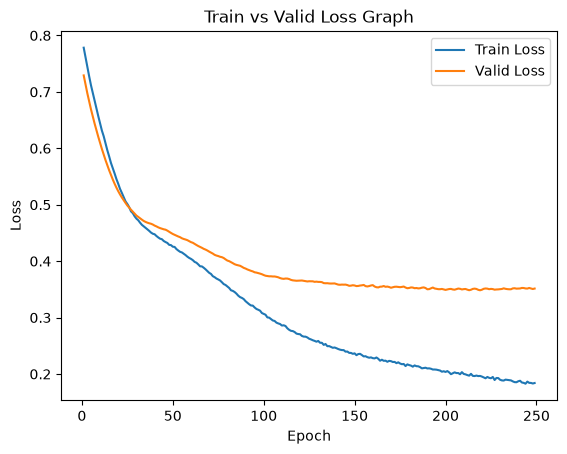

Total Training Time: 0.03 minutes


In [60]:
# 최종 main 함수 실행!!
test_result = main(configs)

### Test 결과 확인

In [61]:
def calculate_scores(model_name, y_actual, y_prediction):
    # y_actual, y_prediction: (wafer 수, 출력 수). y_actual의 NaN(제거된 점)은 모든 지표에서 제외합니다.
    y_actual = np.asarray(y_actual, dtype=float)
    y_prediction = np.asarray(y_prediction, dtype=float)
    if y_actual.ndim == 1:
        y_actual = y_actual.reshape(-1, 1)
    if y_prediction.ndim == 1:
        y_prediction = y_prediction.reshape(-1, 1)
    assert y_actual.shape == y_prediction.shape, (y_actual.shape, y_prediction.shape)
    valid = np.isfinite(y_actual)

    actual = y_actual[valid]
    error = y_prediction[valid] - actual
    r2_per_output = np.array([
        r2_score(y_actual[valid[:, j], j], y_prediction[valid[:, j], j])
        for j in range(y_actual.shape[1]) if valid[:, j].sum() >= 2
    ])
    return {
        'model': model_name,
        'wafers': y_actual.shape[0],
        'MAE': np.abs(error).mean().round(2),                   # 유효 점 전체 기준
        'MAPE': np.mean(np.abs(error) / np.abs(actual)).round(2),
        'RMSE': np.sqrt(np.mean(error ** 2)).round(2),
        'R2_avg': r2_per_output.mean().round(2),         # 출력별 R2 평균
        'R2_min': r2_per_output.min().round(2),          # 가장 못 맞춘 출력
        'R2_max': r2_per_output.max().round(2)
        # 'R2':r2_per_output
    }

In [62]:
calculate_scores(configs['backbone'], test_result['true'], test_result['pred'])

{'model': 'RNN',
 'wafers': 215,
 'MAE': 1975.55,
 'MAPE': 0.25,
 'RMSE': 2869.82,
 'R2_avg': 0.31,
 'R2_min': -0.06,
 'R2_max': 0.47}

-----

In [63]:
model_configs = {
    'backbone': 'RNN',              # 'MLP', 'CNN', 'RNN'

    # common
    'dropout_rate': .1,
    'use_batchnorm': True,

    # MLP
    'mlp_hidden_dims': [256, 64, 32],   # same as test_a_multi -> direct comparison with window_size=1
    
    # 1D CNN
    'cnn_channels': [128, 64],
    'kernel_size': 7,                   # odd number keeps length T with padding=k//2
    'cnn_pool': 'last',                 # 'last' (time step of the target wafer) or 'avg'
    
    # RNN
    'rnn_type': 'RNN',
    'hidden_size': 64,
    'num_layers': 2,
    'bidirectional': True,
}
configs.update(model_configs)


In [64]:
experiments = [
    {'backbone': 'MLP'},
    {'backbone': 'CNN'},
    {'backbone': 'RNN', 'rnn_type': 'RNN'},
    {'backbone': 'RNN', 'rnn_type': 'LSTM'},
    {'backbone': 'RNN', 'rnn_type': 'GRU'},
]

rows = []
for exp in experiments:
    run_configs = {**configs, **exp, 'visualize': False}   # copy; global configs stays unchanged
    result = main(run_configs)
    name = f"{exp['backbone']}{'-' + exp.get('rnn_type', '') if exp['backbone'] == 'RNN' else ''}"
    rows.append(calculate_scores(name, result['true'], result['pred']))
display(pd.DataFrame(rows))

Configurations: 
 {'device': 'cuda', 'seed': 0, 'product': 'A', 'task': 'multi', 'cat_encoding': 'one-hot', 'scaler_type': 'standard', 'train_ratio': 0.6, 'test_ratio': 0.2, 'window_size': 1, 'stride': 1, 'y_mode': 'last', 'batch_size': 256, 'rnn_type': 'RNN', 'hidden_size': 64, 'num_layers': 2, 'bidirectional': True, 'dropout_rate': 0.1, 'use_batchnorm': True, 'backbone': 'MLP', 'optimizer': 'adam', 'lr': 0.0001, 'momentum': 0.9, 'weight_decay': 0.0, 'num_epochs': 500, 'visualize': False, 'save_dir': './results', 'patience': 30, 'mlp_hidden_dims': [256, 64, 32], 'cnn_channels': [128, 64], 'kernel_size': 7, 'cnn_pool': 'last'}
--------------- Epoch: 1 ---------------
Train Loss: 0.9228
Valid Loss: 0.6992
Validation loss decreased (inf --> 0.6992).  Saving model ...
--------------- Epoch: 2 ---------------
Train Loss: 0.9089
Valid Loss: 0.6994
--------------- Epoch: 3 ---------------
Train Loss: 0.8916
Valid Loss: 0.7003
--------------- Epoch: 4 ---------------
Train Loss: 0.8808
Valid 

,model,wafers,MAE,MAPE,RMSE,R2_avg,R2_min,R2_max
0,MLP,215,1949.67,0.25,2857.57,0.33,-0.18,0.48
1,CNN,215,2054.26,0.26,3023.23,0.24,-0.38,0.42
2,RNN-RNN,215,1975.55,0.25,2869.82,0.31,-0.06,0.47
3,RNN-LSTM,215,2018.66,0.25,2938.63,0.28,-0.08,0.44
4,RNN-GRU,215,1987.84,0.25,2917.83,0.30,-0.29,0.47


In [76]:
from matplotlib.colors import LinearSegmentedColormap, Normalize, TwoSlopeNorm
from matplotlib.patches import Rectangle, Circle

# one-hue sequential ramps (light -> dark) and a blue <-> gray <-> red diverging ramp
CMAP_VALUE = LinearSegmentedColormap.from_list('value', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
CMAP_ABS   = LinearSegmentedColormap.from_list('abs_err', ['#fde3d6', '#f6a985', '#eb6834', '#b9471c', '#7a2c0f'])
CMAP_DIFF  = LinearSegmentedColormap.from_list('diff', ['#184f95', '#86b6ef', '#f0efec', '#ee9998', '#b8302f'])
MISSING_COLOR, INK_DARK, INK_LIGHT, INK_MUTED = '#e4e3df', '#0b0b0b', '#ffffff', '#52514e'

def parse_coords(columns):
    """'CapL_(-1,5)' -> (-1, 5) shot-grid index"""
    return np.array([tuple(map(int, re.findall(r'-?\d+', c))) for c in columns])

def _ink_for(rgba):
    r, g, b = rgba[:3]
    return INK_LIGHT if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.5 else INK_DARK

def per_point_r2(y_true, y_pred, min_n=2):
    """측정 위치(컬럼)별 R². calculate_scores의 R2_avg와 같은 정의 (NaN = 제거된 점은 제외)"""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    r2 = np.full(y_true.shape[1], np.nan)
    for j in range(y_true.shape[1]):
        ok = np.isfinite(y_true[:, j])
        if ok.sum() >= min_n:
            r2[j] = r2_score(y_true[ok, j], y_pred[ok, j])
    return r2

def draw_wafer(ax, values, coords, cmap, norm, title, unit_scale=1e3, fmt='{:.1f}', shot_aspect=1.0):
    """Draw one wafer map: one rectangle per shot, colored by value, value written inside."""
    for (x, y), v in zip(coords, values):
        cell = dict(xy=(x - 0.5, (y - 0.5) * shot_aspect), width=1, height=shot_aspect,
                    edgecolor='white', linewidth=1.5)
        if np.isfinite(v):
            color = cmap(norm(v))
            ax.add_patch(Rectangle(facecolor=color, **cell))
            ax.text(x, y * shot_aspect, fmt.format(v / unit_scale), ha='center', va='center',
                    fontsize=7, color=_ink_for(color))
        else:  # removed by 6-sigma rule (or no measurement)
            ax.add_patch(Rectangle(facecolor=MISSING_COLOR, hatch='////', **cell))

    # approximate wafer edge: smallest circle around the grid center that encloses every shot
    cx = (coords[:, 0].min() + coords[:, 0].max()) / 2
    cy = (coords[:, 1].min() + coords[:, 1].max()) / 2 * shot_aspect
    corners = np.array([(x + dx, (y + dy) * shot_aspect) for x, y in coords
                        for dx in (-0.5, 0.5) for dy in (-0.5, 0.5)])
    radius = np.sqrt(((corners - (cx, cy)) ** 2).sum(axis=1)).max() * 1.02
    ax.add_patch(Circle((cx, cy), radius, fill=False, edgecolor='#b5b4ae', linewidth=1))

    ax.set_xlim(cx - radius - 0.3, cx + radius + 0.3)
    ax.set_ylim(cy - radius - 0.3, cy + radius + 0.3)
    ax.set_aspect('equal')
    ax.set_xticks(np.unique(coords[:, 0]))
    ax.set_yticks(np.unique(coords[:, 1]) * shot_aspect, np.unique(coords[:, 1]))
    ax.tick_params(labelsize=7, colors=INK_MUTED, length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(title, fontsize=11, color=INK_DARK, loc='left')


def plot_wafer_comparison(y_true, y_pred, y_cols, wafer_idx=None, shot_aspect=1.3, suptitle=None, third='mae'):
    """
    wafer_idx=None -> test 요약 (mean actual / mean prediction / third 패널)
        third='mae' -> 위치별 MAE,  third='r2' -> 위치별 R² (test wafer 간)
    wafer_idx=int  -> wafer 하나 (actual / prediction / prediction - actual)
    """
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    coords = parse_coords(y_cols)
    valid = np.isfinite(y_true)
    third_scale, third_fmt = 1e3, '{:.1f}'          # CapL 단위 패널은 x10^3으로 표시

    if wafer_idx is None:
        actual = np.nanmean(y_true, axis=0)
        predicted = np.nanmean(np.where(valid, y_pred, np.nan), axis=0)
        r2_point = per_point_r2(y_true, y_pred)
        mae = np.nanmean(np.abs(y_pred - y_true))
        if third == 'r2':
            third_values, third_title = r2_point, 'R² per point (across wafers)'
            third_cmap = CMAP_DIFF.reversed()      # 파랑 = 잘 맞춤, 빨강 = 평균보다 못함(R² < 0)
            third_norm = TwoSlopeNorm(vcenter=0, vmin=min(np.nanmin(r2_point), -0.05),
                                      vmax=max(np.nanmax(r2_point), 0.05))
            third_scale, third_fmt = 1, '{:.2f}'
        else:
            third_values = np.nanmean(np.abs(y_pred - y_true), axis=0)
            third_title, third_cmap = 'MAE per point', CMAP_ABS
            third_norm = Normalize(0, np.nanmax(third_values))
        names = ('Actual (mean)', 'Predicted (mean)')
        suptitle = suptitle or (f'Test wafers (n={len(y_true)}), CapL x$10^3$  '
                                f'(MAE {mae:,.0f},  R² avg over points {np.nanmean(r2_point):.2f})')
    else:
        actual, predicted = y_true[wafer_idx], y_pred[wafer_idx]
        third_values = predicted - actual
        third_title, third_cmap = 'Predicted − Actual', CMAP_DIFF
        limit = np.nanmax(np.abs(third_values))
        third_norm = TwoSlopeNorm(vcenter=0, vmin=-limit, vmax=limit)
        names = ('Actual', 'Predicted')
        ok = np.isfinite(actual)
        mae = np.nanmean(np.abs(third_values))
        r2_wafer = r2_score(actual[ok], predicted[ok])           # 수준(offset) + 패턴을 함께 봄
        r_pattern = np.corrcoef(actual[ok], predicted[ok])[0, 1]  # 수준 무시, 공간 패턴 모양만 봄
        suptitle = suptitle or (f'Test wafer #{wafer_idx}, CapL x$10^3$  '
                                f'(MAE {mae:,.0f},  R² within wafer {r2_wafer:.2f},  pattern r {r_pattern:.2f})')

    both = np.concatenate([actual[np.isfinite(actual)], predicted[np.isfinite(predicted)]])
    value_norm = Normalize(*np.percentile(both, [2, 98]))

    fig, axes = plt.subplots(1, 3, figsize=(17, 6), constrained_layout=True)
    draw_wafer(axes[0], actual, coords, CMAP_VALUE, value_norm, names[0], shot_aspect=shot_aspect)
    draw_wafer(axes[1], predicted, coords, CMAP_VALUE, value_norm, names[1], shot_aspect=shot_aspect)
    draw_wafer(axes[2], third_values, coords, third_cmap, third_norm, third_title,
               unit_scale=third_scale, fmt=third_fmt, shot_aspect=shot_aspect)

    for norm, cmap, ax_list, scale, fmt in [(value_norm, CMAP_VALUE, axes[:2], 1e3, '{:.1f}'),
                                            (third_norm, third_cmap, axes[2], third_scale, third_fmt)]:
        cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax_list, shrink=0.75, pad=0.02)
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _, s=scale, f=fmt: f.format(v / s)))
        cbar.ax.tick_params(labelsize=8, colors=INK_MUTED)
        cbar.outline.set_visible(False)
    fig.suptitle(suptitle, fontsize=13, color=INK_DARK, x=0.01, ha='left')
    return fig

In [84]:
mlp_result = main({**configs, 'backbone': 'MLP', 'visualize': False})
true, pred = mlp_result['true'], mlp_result['pred']

Configurations: 
 {'device': 'cuda', 'seed': 0, 'product': 'A', 'task': 'multi', 'cat_encoding': 'one-hot', 'scaler_type': 'standard', 'train_ratio': 0.6, 'test_ratio': 0.2, 'window_size': 1, 'stride': 1, 'y_mode': 'last', 'batch_size': 256, 'rnn_type': 'RNN', 'hidden_size': 64, 'num_layers': 2, 'bidirectional': True, 'dropout_rate': 0.1, 'use_batchnorm': True, 'backbone': 'MLP', 'optimizer': 'adam', 'lr': 0.0001, 'momentum': 0.9, 'weight_decay': 0.0, 'num_epochs': 500, 'visualize': False, 'save_dir': './results', 'patience': 30, 'mlp_hidden_dims': [256, 64, 32], 'cnn_channels': [128, 64], 'kernel_size': 7, 'cnn_pool': 'last'}
--------------- Epoch: 1 ---------------
Train Loss: 0.9228
Valid Loss: 0.6992
Validation loss decreased (inf --> 0.6992).  Saving model ...
--------------- Epoch: 2 ---------------
Train Loss: 0.9089
Valid Loss: 0.6994
--------------- Epoch: 3 ---------------
Train Loss: 0.8916
Valid Loss: 0.7003
--------------- Epoch: 4 ---------------
Train Loss: 0.8808
Valid 

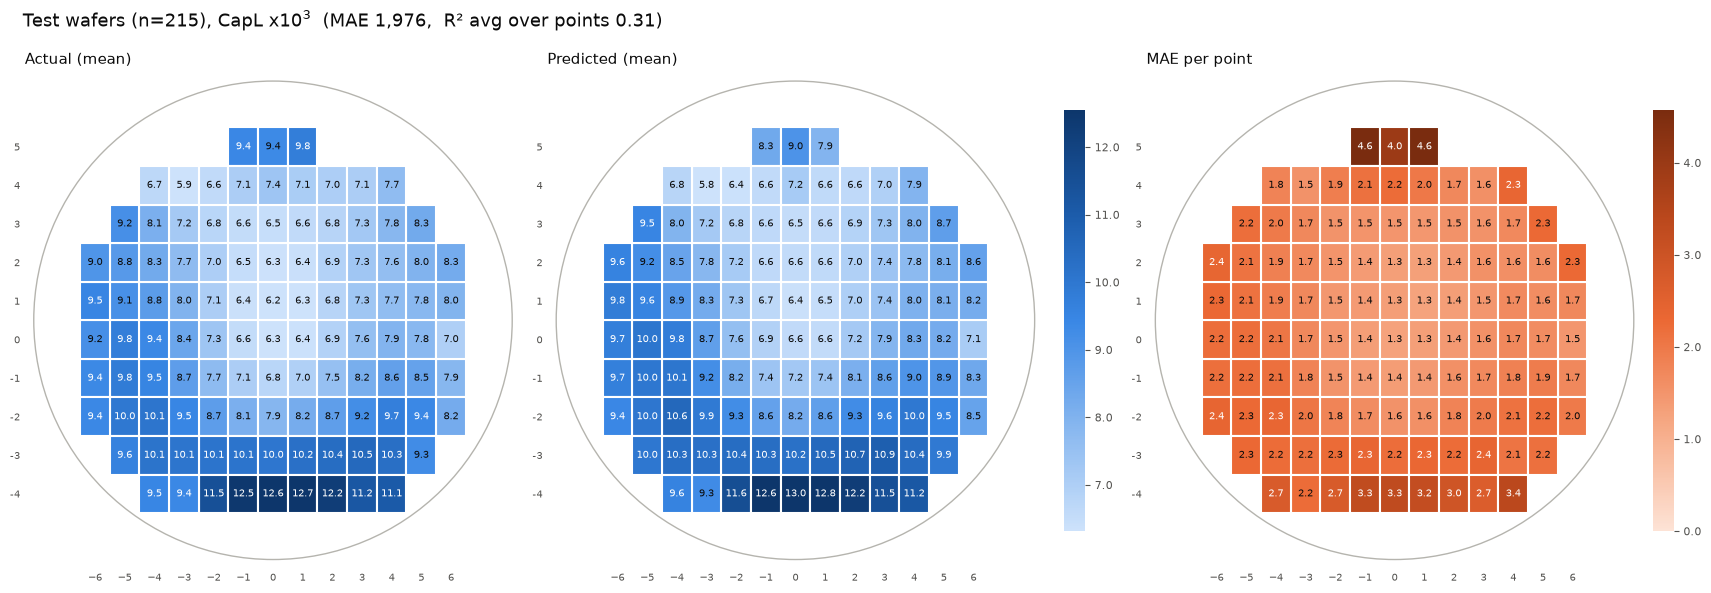

In [ ]:
# 1) whole test set
plot_wafer_comparison(true, pred, y_cols, third='mae'); plt.show()

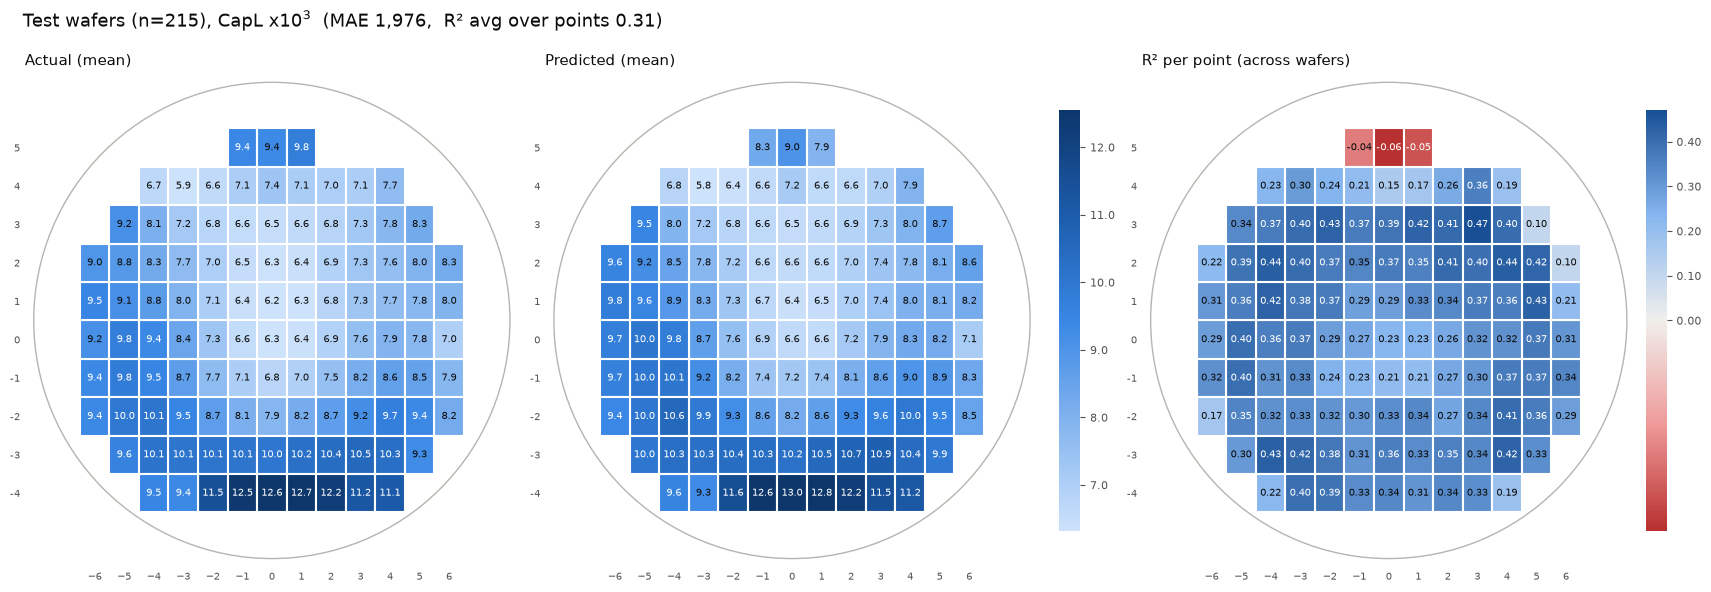

In [81]:
plot_wafer_comparison(true, pred, y_cols, third='r2'); plt.show()

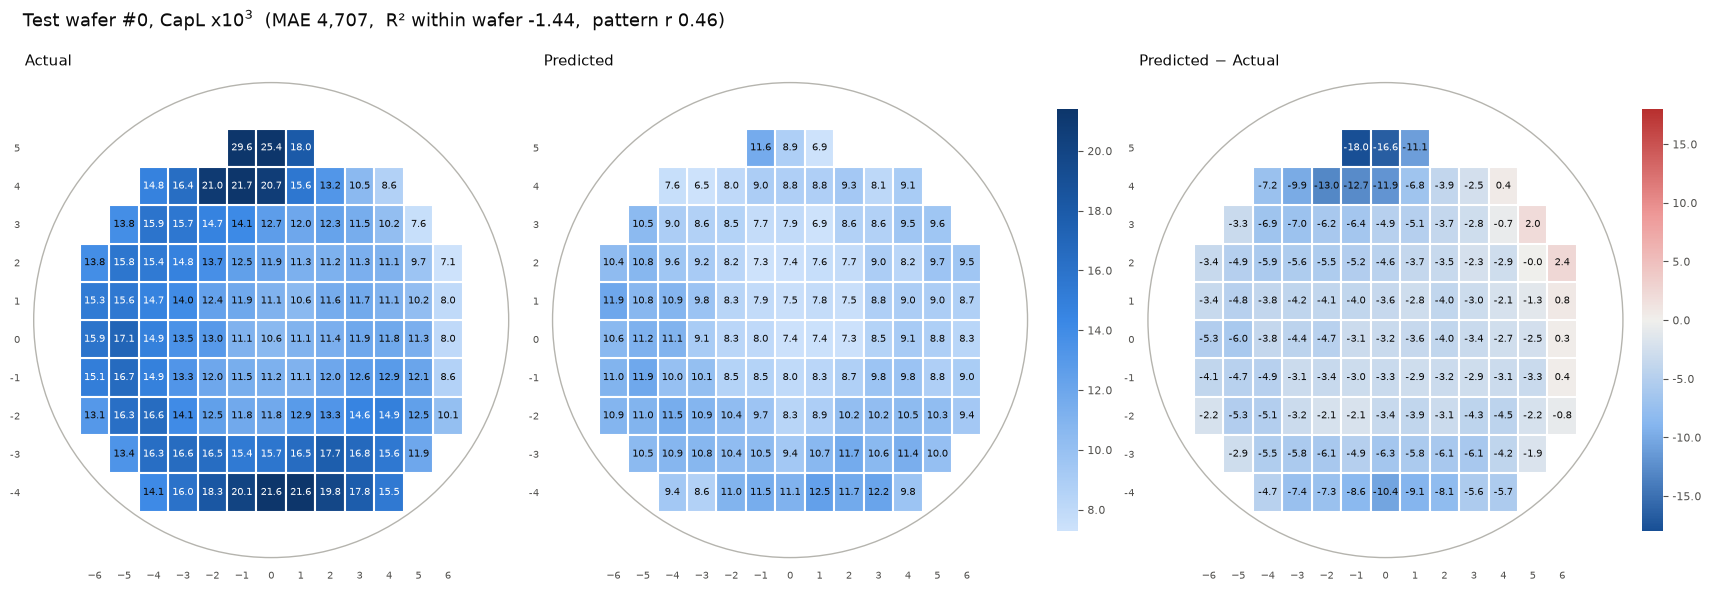

In [95]:
plot_wafer_comparison(true, pred, y_cols, wafer_idx=0); plt.show()

In [ ]:
def _identity_axes(ax, t, p, pad=0.03):
    lo, hi = np.nanmin([t.min(), p.min()]), np.nanmax([t.max(), p.max()])
    lo, hi = lo - pad * (hi - lo), hi + pad * (hi - lo)
    ax.plot([lo, hi], [lo, hi], color=INK_MUTED, lw=1, ls='--', zorder=0)   # y = x (완벽한 예측)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect('equal')


def plot_scatter_all_points(y_true, y_pred, title='All CapL points (test)'):
    """(wafer, 위치) 쌍 전체를 한 장에"""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    ok = np.isfinite(y_true)
    t, p = y_true[ok], y_pred[ok]
    r2_pooled = r2_score(t, p)                         # 위치 간 평균 차이까지 포함 -> 보통 R2_avg보다 큼
    r2_avg = np.nanmean(per_point_r2(y_true, y_pred))  # calculate_scores의 R2_avg

    fig, ax = plt.subplots(figsize=(6.5, 6))
    hb = ax.hexbin(t, p, gridsize=60, bins='log', cmap=CMAP_VALUE, mincnt=1)
    _identity_axes(ax, t, p)
    # fig.colorbar(hb, ax=ax, shrink=0.8, label='count (log)')
    ax.set(xlabel='Actual CapL', ylabel='Predicted CapL',
           title=f'{title}\nn={ok.sum():,} points | MAE {np.abs(p - t).mean():,.0f} | '
                 f'R² pooled {r2_pooled:.2f} | R² avg over points {r2_avg:.2f}')
    ax.title.set_fontsize(10)
    plt.tight_layout()
    return fig


def plot_scatter_by_point(y_true, y_pred, y_cols, shot_aspect=1.0):
    """108개 위치별 scatter를 wafer 배치대로. 숫자/테두리 색 = 그 위치의 R²"""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    coords = parse_coords(y_cols)
    r2_point = per_point_r2(y_true, y_pred)
    xs = np.arange(coords[:, 0].min(), coords[:, 0].max() + 1)
    ys = np.arange(coords[:, 1].max(), coords[:, 1].min() - 1, -1)
    fig, axes = plt.subplots(len(ys), len(xs), figsize=(1.6 * len(xs), 1.6 * len(ys) * shot_aspect))
    for ax in axes.ravel():
        ax.set_axis_off()
    r2_norm = TwoSlopeNorm(vcenter=0, vmin=min(np.nanmin(r2_point), -0.05), vmax=max(np.nanmax(r2_point), 0.05))
    for j, (x, y) in enumerate(coords):
        ax = axes[np.where(ys == y)[0][0], np.where(xs == x)[0][0]]
        ok = np.isfinite(y_true[:, j])
        ax.set_axis_on()
        ax.scatter(y_true[ok, j], y_pred[ok, j], s=3, alpha=0.5, color='#1c5cab', linewidths=0)
        _identity_axes(ax, y_true[ok, j], y_pred[ok, j])
        ax.set_xticks([]); ax.set_yticks([])
        color = CMAP_DIFF.reversed()(r2_norm(r2_point[j]))
        for spine in ax.spines.values():
            spine.set_edgecolor(color); spine.set_linewidth(2.5)
        ax.text(0.04, 0.96, f'({x},{y})\nR² {r2_point[j]:.2f}', transform=ax.transAxes,
                ha='left', va='top', fontsize=6.5, color=INK_DARK)
    fig.suptitle(f'Predicted (y) vs Actual (x) per point, test wafers — R² avg {np.nanmean(r2_point):.2f}, '
                 f'min {np.nanmin(r2_point):.2f}, max {np.nanmax(r2_point):.2f}', x=0.01, ha='left', fontsize=13)
    fig.tight_layout()
    return fig

def plot_scatter_median(y_true, y_pred, title='Wafer CapL median (test)'):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    t = np.nanmedian(y_true, axis=1)
    p = np.nanmedian(np.where(np.isfinite(y_true), y_pred, np.nan), axis=1)
    r2 = r2_score(t, p)
    rho = stats.spearmanr(t, p).statistic                # 순위가 맞는지 (큰 wafer를 크다고 하는지)

    fig, ax = plt.subplots(figsize=(6.5, 6))
    sc = ax.scatter(t, p, c=np.arange(len(t)), cmap='viridis', s=18, alpha=0.85, linewidths=0)
    _identity_axes(ax, t, p)
    fig.colorbar(sc, ax=ax, shrink=0.8, label='test wafer order (time →)')
    ax.set(xlabel='Actual median CapL', ylabel='Predicted median CapL',
           title=f'{title}\nn={len(t)} wafers | MAE {np.abs(p - t).mean():,.0f} | '
                 f'R² {r2:.2f} | Spearman ρ {rho:.2f}')
    ax.title.set_fontsize(10)
    plt.tight_layout()
    return fig

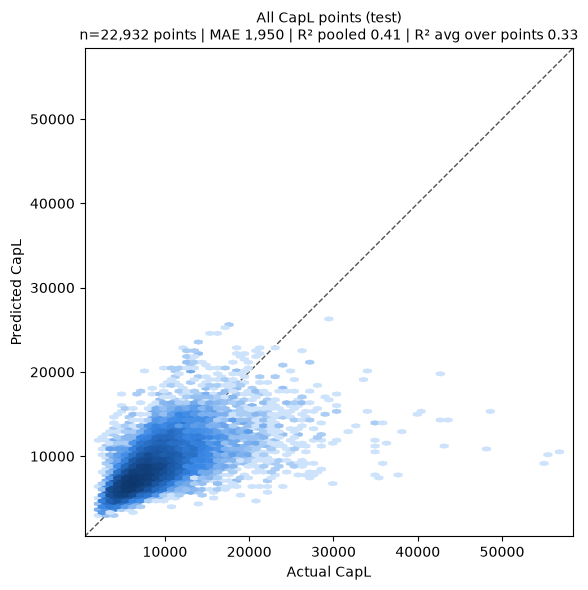

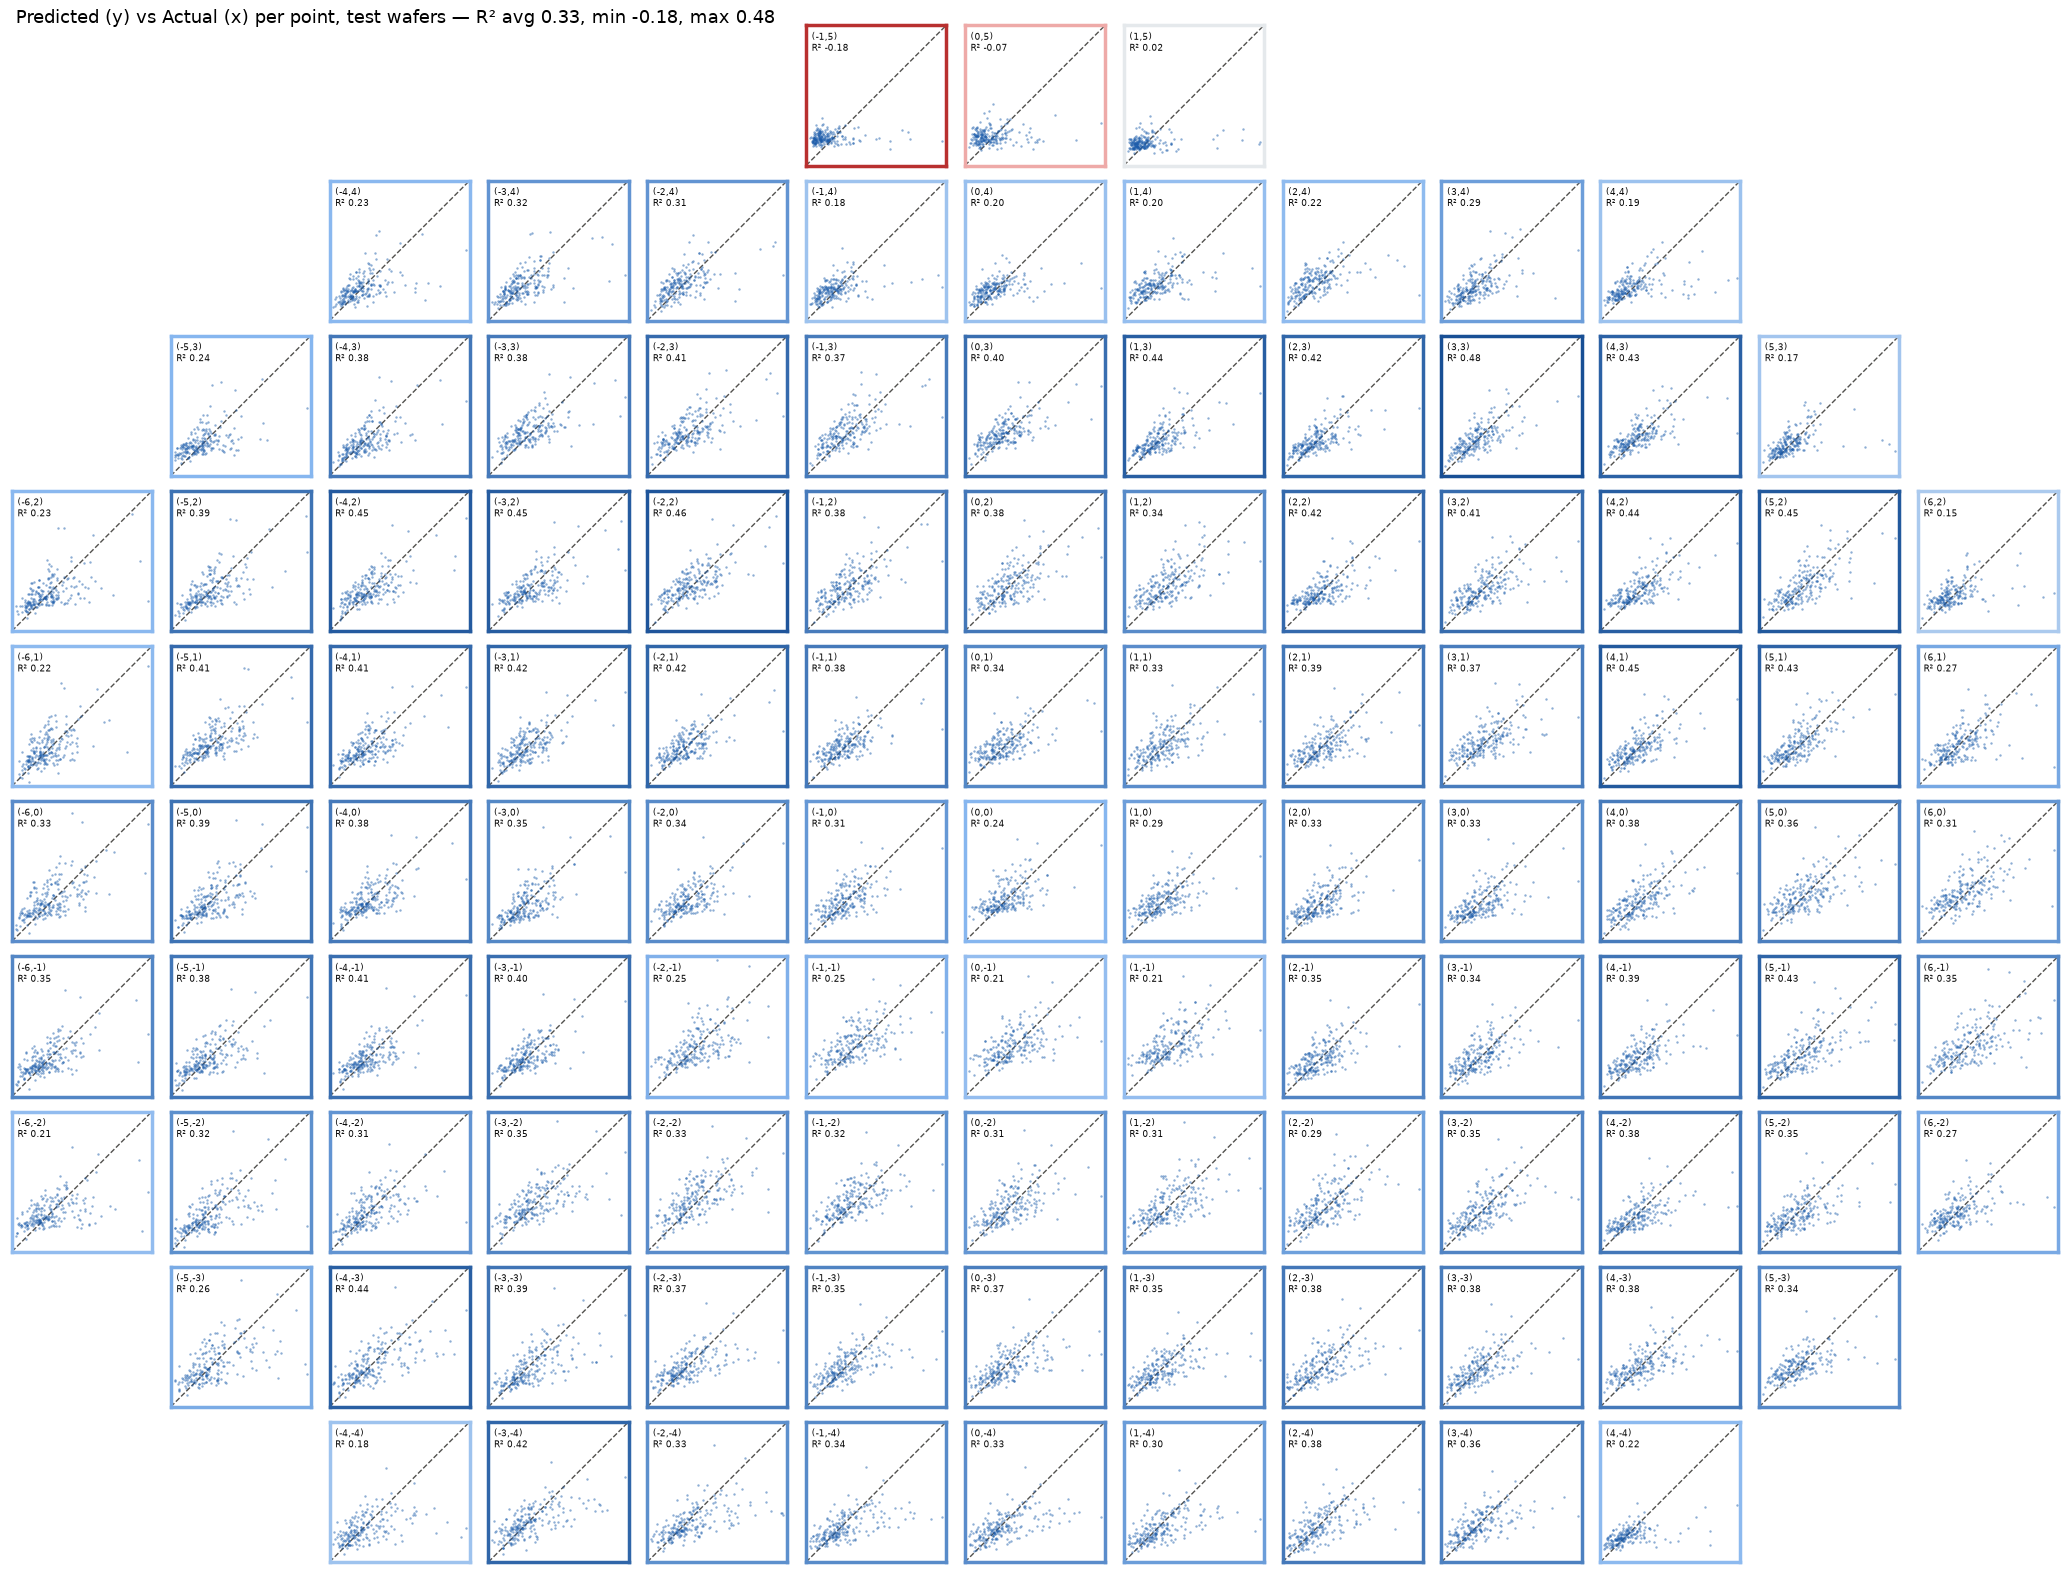

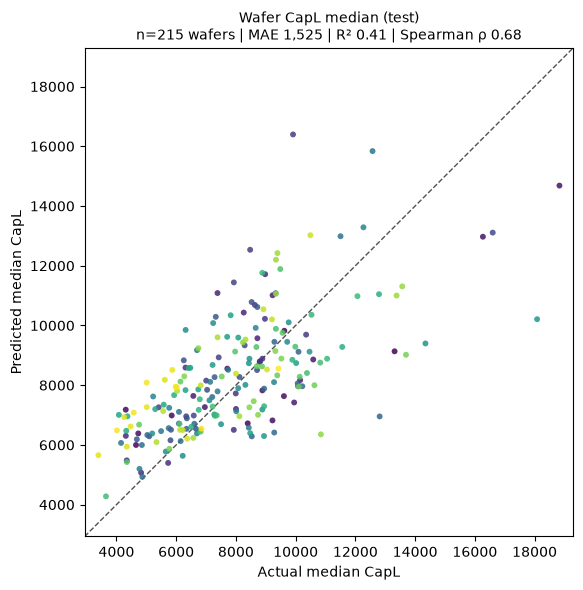

In [99]:
plot_scatter_all_points(true, pred); plt.show()
plot_scatter_by_point(true, pred, y_cols); plt.show()
plot_scatter_median(true, pred); plt.show()